# Notebook 2 — Feature Relationships, Dimensionality Reduction & Feature Selection

Cross-feature analysis, PCA, t-SNE, and model-based feature selection on the *Student Social Media and Mental Health Impact* dataset.

## 0. Setup & Data Loading

In [4]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
import seaborn as sns
from scipy import stats

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import (
    mutual_info_regression, RFE, RFECV
)
from sklearn.inspection import permutation_importance
from sklearn.model_selection import KFold

sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams['figure.dpi'] = 110

DATA_PATH = '../dataset/Student Social Media And Mental Health Impact.csv'
df = pd.read_csv(DATA_PATH)

STRESS_ORDER  = ['Low', 'Medium', 'High', 'Very High']
df['Stress_Level'] = pd.Categorical(df['Stress_Level'], categories=STRESS_ORDER, ordered=True)

NUMERIC_COLS     = ['Age', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks',
                    'Study_Hours', 'Physical_Activity_Hours',
                    'Sleep_Hours_Per_Night', 'Mental_Health_Score']
CATEGORICAL_COLS = ['Gender', 'Country', 'Academic_Level',
                    'Most_Used_Platform', 'Purpose_Of_Use']
TARGET = 'Mental_Health_Score'

# Ordinal encoding for Stress_Level
stress_map = {lvl: i for i, lvl in enumerate(STRESS_ORDER)}
df['Stress_Level_Enc'] = df['Stress_Level'].map(stress_map)

print('Shape:', df.shape)
df.head()

Shape: (5000, 14)


,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score,Stress_Level_Enc
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8,1
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6,0
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0,1
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3,3
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4,3


## 1. Correlation Analysis — Numeric Features

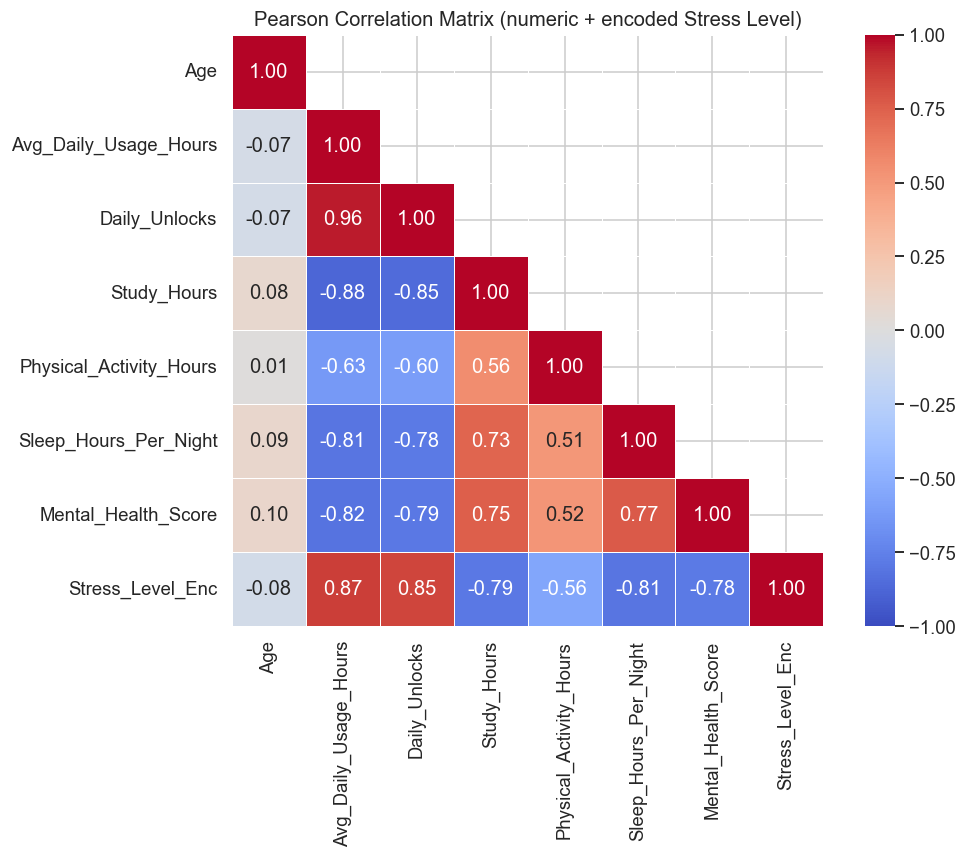


Top-5 correlations with Mental_Health_Score:
Avg_Daily_Usage_Hours    0.816453
Daily_Unlocks            0.790851
Stress_Level_Enc         0.782976
Sleep_Hours_Per_Night    0.766430
Study_Hours              0.752626


In [5]:
corr_cols = NUMERIC_COLS + ['Stress_Level_Enc']
corr_matrix = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
sns.heatmap(
    corr_matrix, annot=True, fmt='.2f', cmap='coolwarm',
    center=0, vmin=-1, vmax=1, mask=mask,
    square=True, linewidths=0.5, ax=ax
)
ax.set_title('Pearson Correlation Matrix (numeric + encoded Stress Level)')
plt.tight_layout()
plt.show()

# Top-5 correlations with target
target_corr = corr_matrix[TARGET].drop(TARGET).abs().sort_values(ascending=False)
print('\nTop-5 correlations with Mental_Health_Score:')
print(target_corr.head(5).to_string())

## 2. Scatter Matrix

# 2.a Pair plot

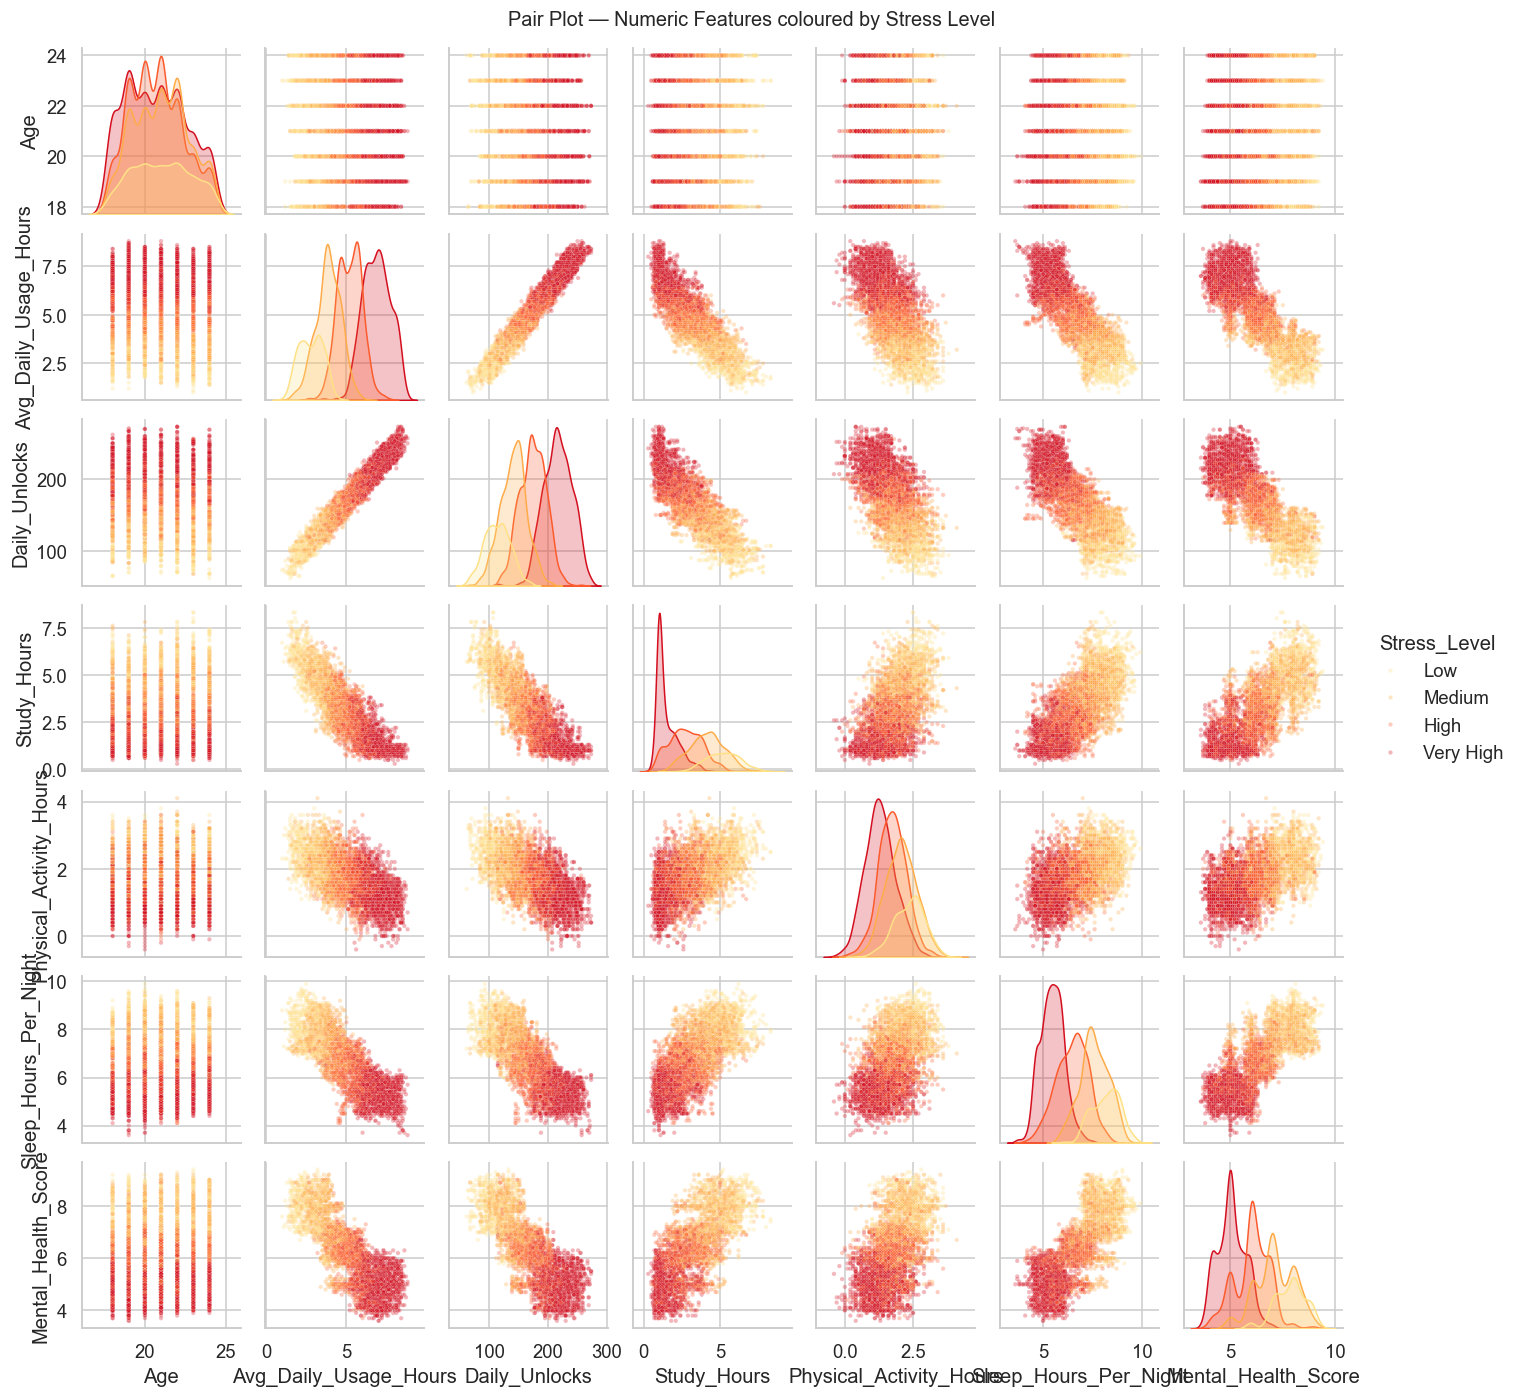

In [6]:
pair_df = df[NUMERIC_COLS].copy()
pair_df['Stress_Level'] = df['Stress_Level']

stress_palette = dict(zip(STRESS_ORDER, sns.color_palette('YlOrRd', 4)))

g = sns.pairplot(
    pair_df,
    hue='Stress_Level',
    hue_order=STRESS_ORDER,
    palette=stress_palette,
    diag_kind='kde',
    plot_kws=dict(alpha=0.3, s=8),
    height=1.8
)
g.figure.suptitle('Pair Plot — Numeric Features coloured by Stress Level',
                  y=1.01, fontsize=13)
plt.show()

### 2a. 3D Scatter — Sleep × Physical Activity × Mental Health

Three key numeric features plotted together (Sleep Hours, Physical Activity Hours,
Mental Health Score), colored by **Stress Level**. The plot is rendered from two
different viewing angles so the cluster structure is visible without interactive rotation.

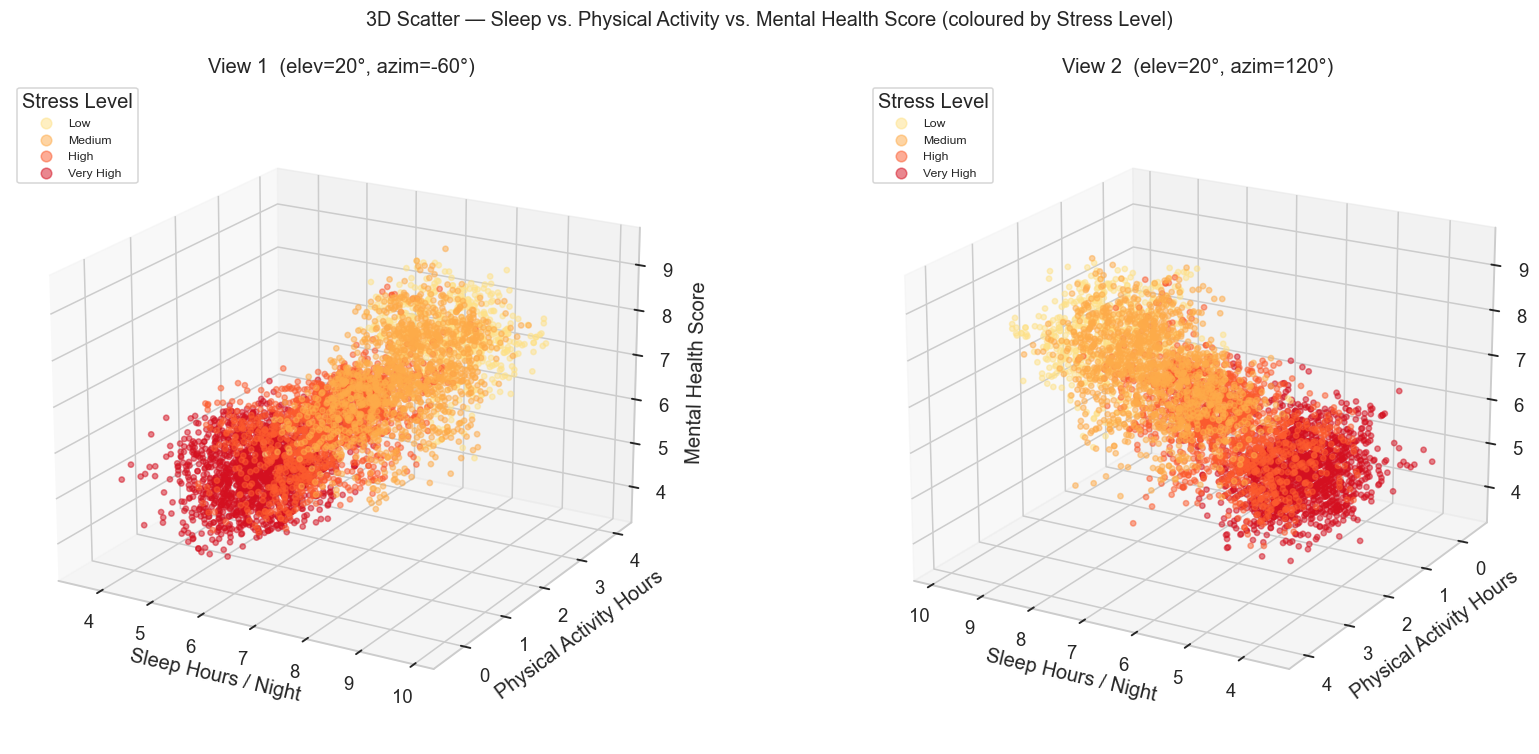

In [7]:
# 3D scatter: Sleep Hours (x) × Physical Activity (y) × Mental Health Score (z)
# coloured by Stress Level, rendered from two viewing angles.
stress_palette = sns.color_palette('YlOrRd', 4)

x = df['Sleep_Hours_Per_Night']
y = df['Physical_Activity_Hours']
z = df[TARGET]

views = [(20, -60), (20, 120)]  # (elevation, azimuth) for the two sides

fig = plt.figure(figsize=(16, 7))

for i, (elev, azim) in enumerate(views):
    ax = fig.add_subplot(1, 2, i + 1, projection='3d')
    for j, lvl in enumerate(STRESS_ORDER):
        mask = df['Stress_Level'] == lvl
        ax.scatter(x[mask], y[mask], z[mask],
                   s=12, alpha=0.5, color=stress_palette[j], label=lvl)
    ax.set_xlabel('Sleep Hours / Night')
    ax.set_ylabel('Physical Activity Hours')
    ax.set_zlabel('Mental Health Score')
    ax.view_init(elev=elev, azim=azim)
    ax.set_title(f'View {i + 1}  (elev={elev}°, azim={azim}°)')
    ax.legend(title='Stress Level', markerscale=2, fontsize=8, loc='upper left')

fig.suptitle('3D Scatter — Sleep vs. Physical Activity vs. Mental Health Score '
             '(coloured by Stress Level)', fontsize=13)
plt.tight_layout()
plt.show()

## 3. Target vs. Each Numeric Feature

**Understanding the p-value.** Each regression line reports a **p-value** whose *null hypothesis* is that the slope is **zero** (no linear relationship between the feature and Mental Health Score). A small **p-value (≤ 0.05)** means the slope is **significantly different from zero** — i.e. the feature is linearly associated with the target.

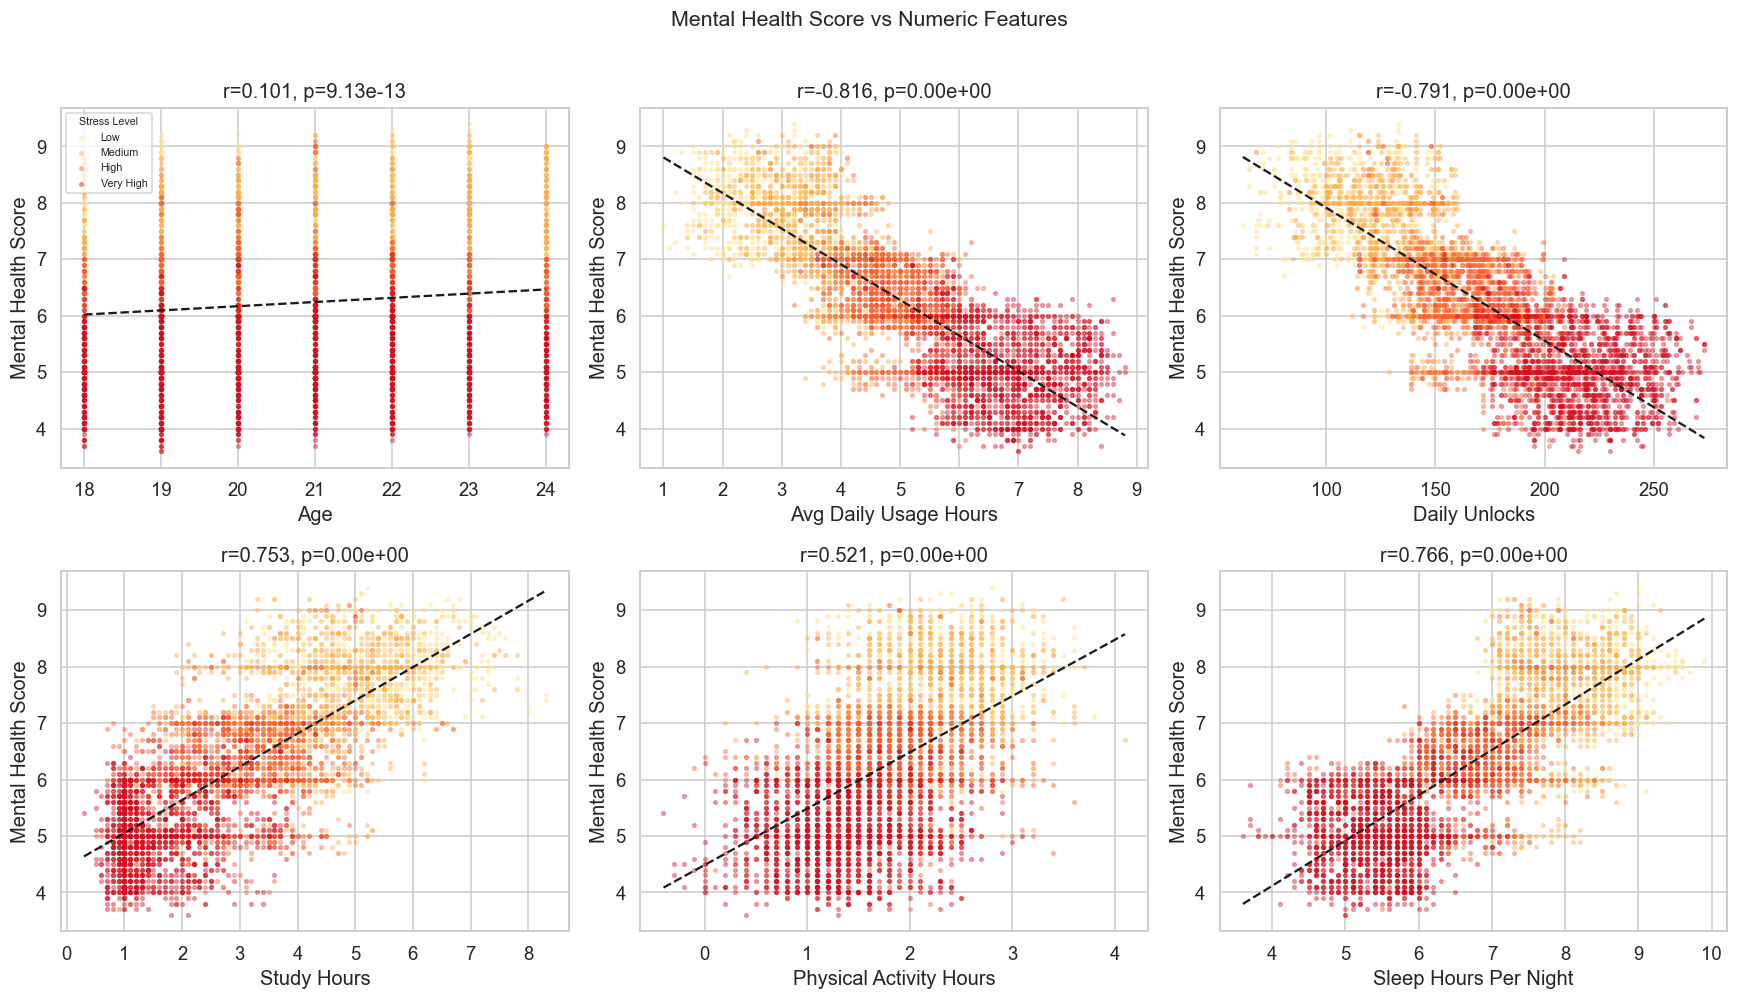

In [8]:
feature_cols = [c for c in NUMERIC_COLS if c != TARGET]
stress_palette_list = sns.color_palette('YlOrRd', 4)

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(feature_cols):
    ax = axes[i]
    for j, lvl in enumerate(STRESS_ORDER):
        mask = df['Stress_Level'] == lvl
        ax.scatter(df.loc[mask, col], df.loc[mask, TARGET],
                   s=6, alpha=0.35, color=stress_palette_list[j], label=lvl)
    # regression line
    m, b, r, p, _ = stats.linregress(df[col], df[TARGET])
    x_range = np.linspace(df[col].min(), df[col].max(), 200)
    ax.plot(x_range, m * x_range + b, 'k--', lw=1.5)
    ax.set_xlabel(col.replace('_', ' '))
    ax.set_ylabel('Mental Health Score')
    p_str = f'{p:.2e}' if p < 0.001 else f'{p:.4f}'
    ax.set_title(f'r={r:.3f}, p={p_str}')
    if i == 0:
        ax.legend(fontsize=7, title='Stress Level', title_fontsize=7)

fig.suptitle('Mental Health Score vs Numeric Features', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

## 4. Categorical Feature vs. Target (ANOVA)

**Understanding the p-value.** ANOVA's *null hypothesis* is that **all group means are equal**. The **p-value** is the probability of seeing group differences this large by chance if the means were actually identical.

- **p ≤ 0.05** → at least one category's mean **differs significantly**
- **p > 0.05** → no significant difference between the groups

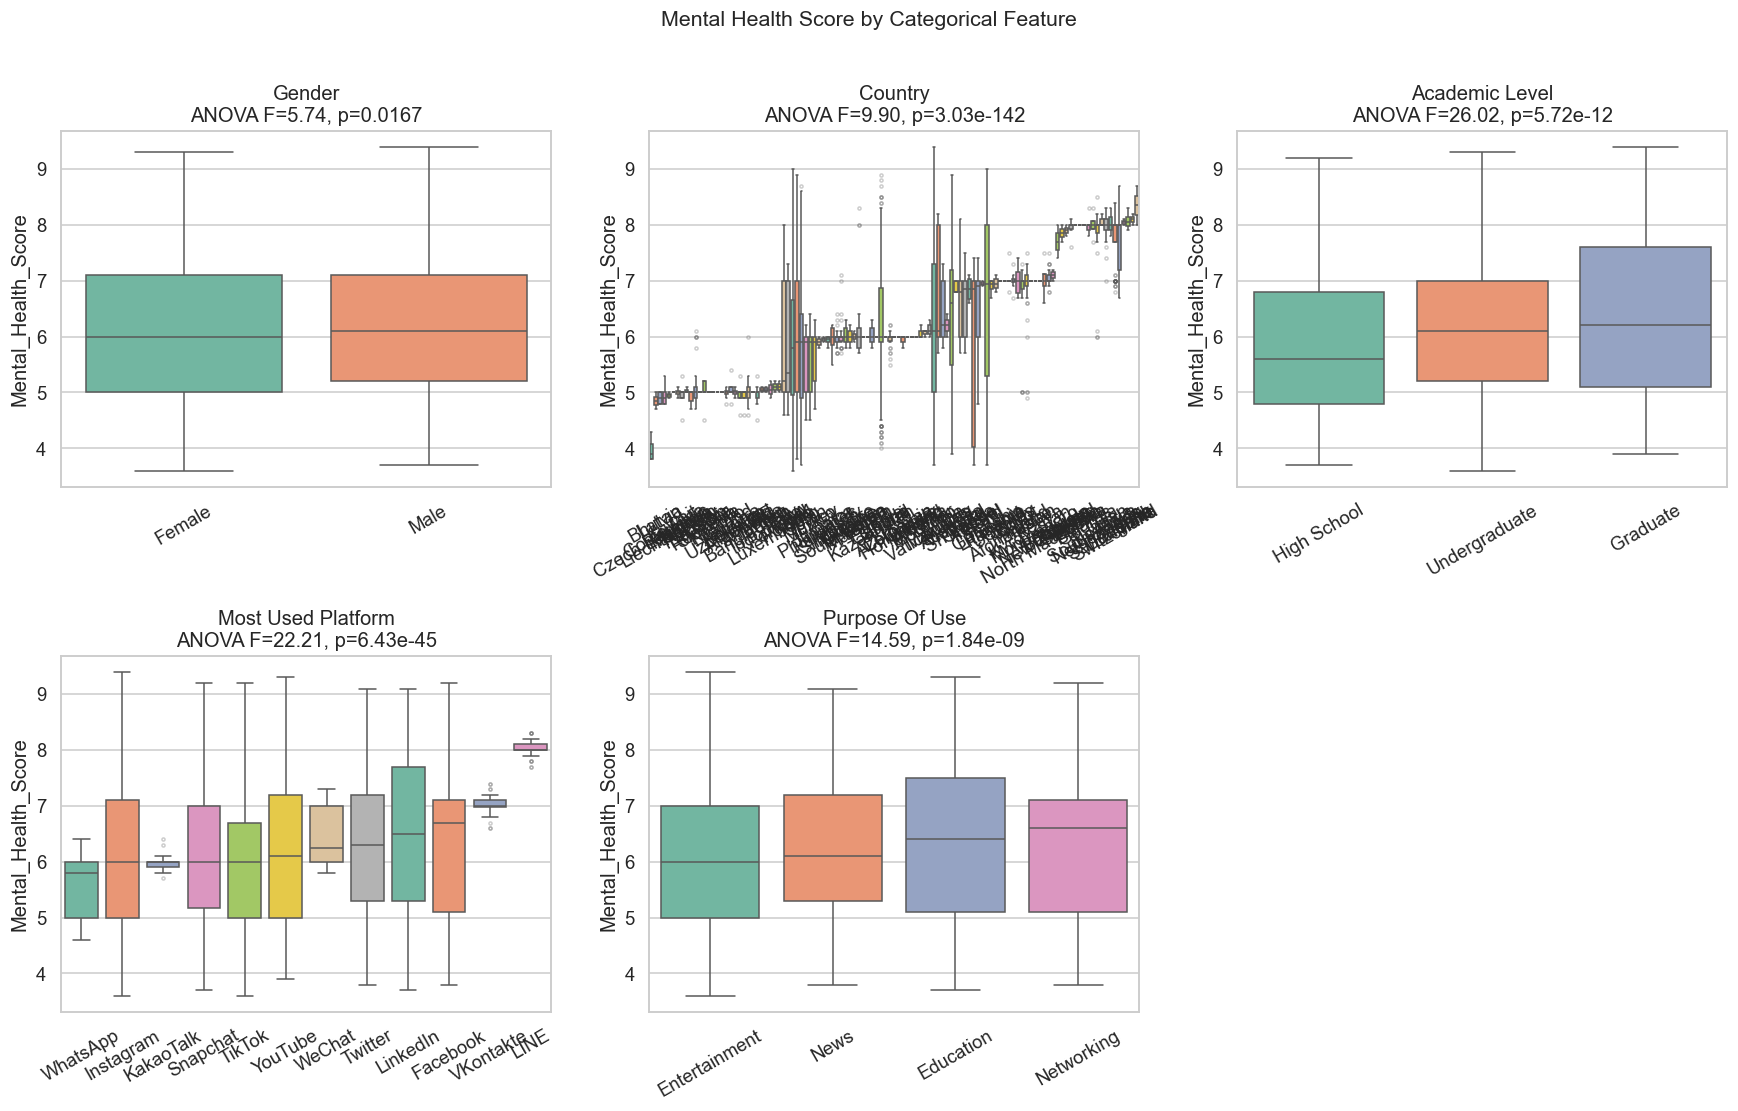

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(CATEGORICAL_COLS):
    ax = axes[i]
    order = df.groupby(col)[TARGET].median().sort_values().index.tolist()
    sns.boxplot(data=df, x=col, y=TARGET, order=order,
                palette='Set2', ax=ax,
                flierprops=dict(marker='o', markersize=2, alpha=0.3))
    groups = [df.loc[df[col] == cat, TARGET].values for cat in order]
    f_stat, p_val = stats.f_oneway(*groups)
    p_str = f'{p_val:.2e}' if p_val < 0.001 else f'{p_val:.4f}'
    ax.set_title(f'{col.replace("_", " ")}\nANOVA F={f_stat:.2f}, p={p_str}')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=30)

axes[-1].set_visible(False)
fig.suptitle('Mental Health Score by Categorical Feature', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

## 5. Stress Level as Pivot — Grouped Bar Charts

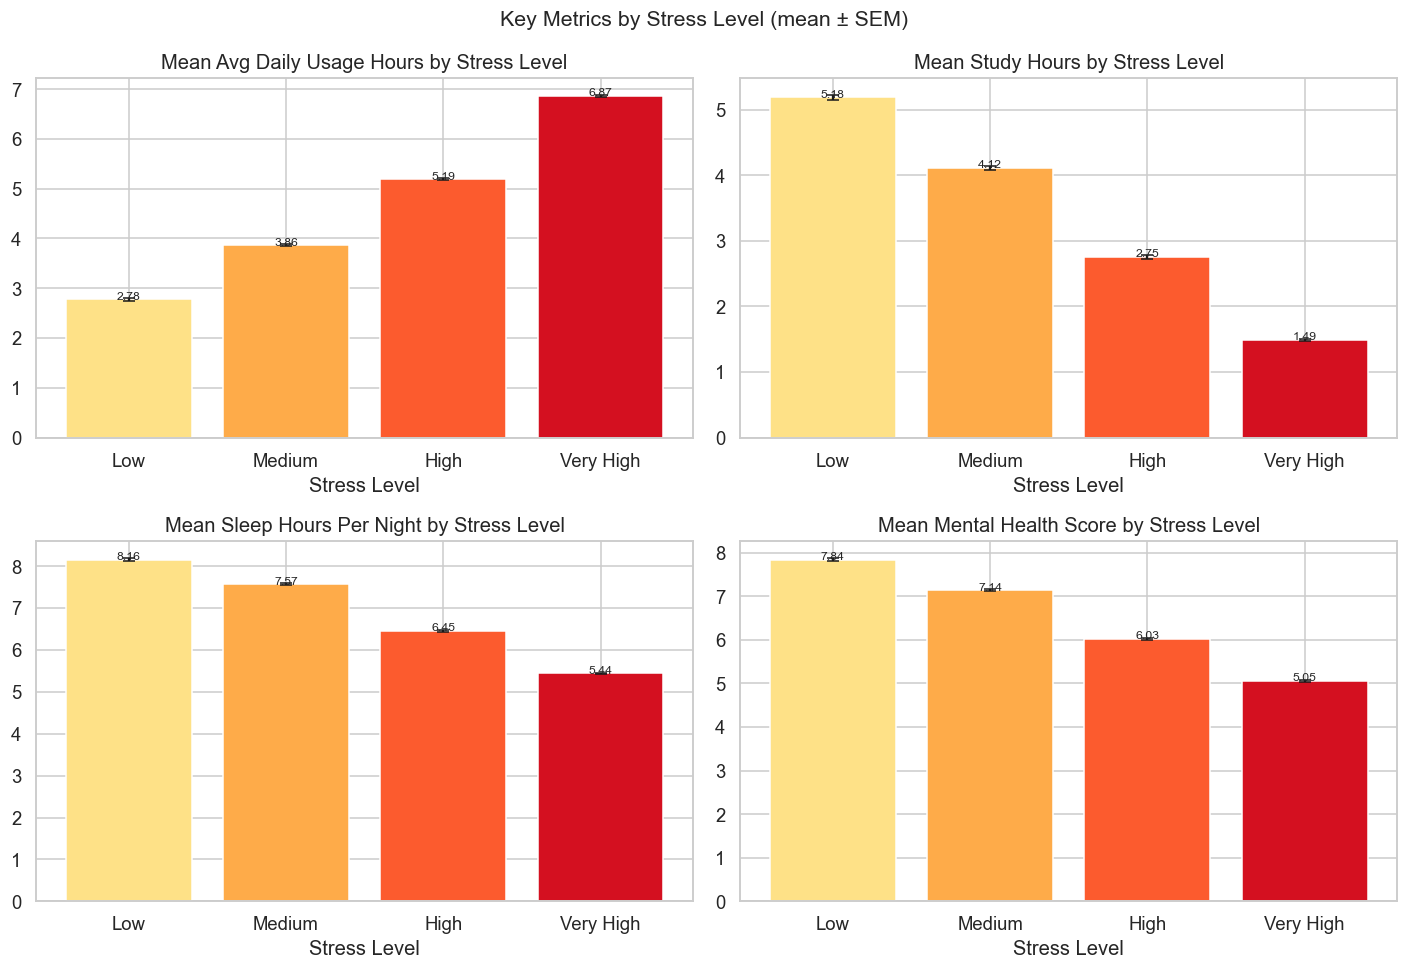

In [10]:
pivot_cols = ['Avg_Daily_Usage_Hours', 'Study_Hours',
              'Sleep_Hours_Per_Night', 'Mental_Health_Score']
stress_palette = sns.color_palette('YlOrRd', 4)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes = axes.flatten()

for i, col in enumerate(pivot_cols):
    ax = axes[i]
    means = df.groupby('Stress_Level', observed=True)[col].mean()[STRESS_ORDER]
    sems  = df.groupby('Stress_Level', observed=True)[col].sem()[STRESS_ORDER]
    bars = ax.bar(STRESS_ORDER, means.values, color=stress_palette,
                  yerr=sems.values, capsize=4, edgecolor='white')
    for bar, v in zip(bars, means.values):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + sems.values.max() * 0.1,
                f'{v:.2f}', ha='center', fontsize=8)
    ax.set_title(f'Mean {col.replace("_", " ")} by Stress Level')
    ax.set_xlabel('Stress Level')

fig.suptitle('Key Metrics by Stress Level (mean ± SEM)', fontsize=14)
plt.tight_layout()
plt.show()

## 6. Platform & Purpose Heatmaps

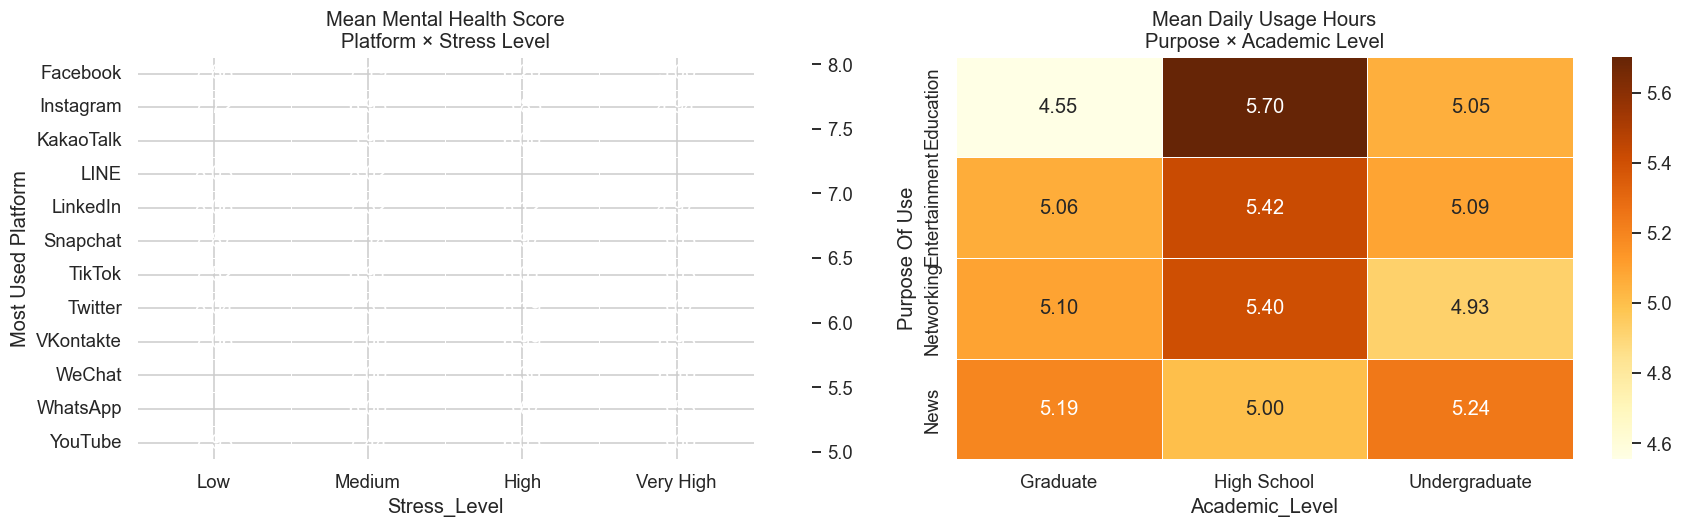

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Heatmap 1: Mean Mental_Health_Score — Platform × Stress Level
pivot1 = df.pivot_table(
    values=TARGET,
    index='Most_Used_Platform',
    columns='Stress_Level',
    aggfunc='mean'
)[STRESS_ORDER]
sns.heatmap(pivot1, annot=True, fmt='.2f', cmap='RdYlGn',
            center=pivot1.values.mean(), ax=axes[0], linewidths=0.4)
axes[0].set_title('Mean Mental Health Score\nPlatform × Stress Level')
axes[0].set_ylabel('Most Used Platform')

# Heatmap 2: Mean Daily Usage — Purpose × Academic Level
pivot2 = df.pivot_table(
    values='Avg_Daily_Usage_Hours',
    index='Purpose_Of_Use',
    columns='Academic_Level',
    aggfunc='mean'
)
sns.heatmap(pivot2, annot=True, fmt='.2f', cmap='YlOrBr',
            ax=axes[1], linewidths=0.4)
axes[1].set_title('Mean Daily Usage Hours\nPurpose × Academic Level')
axes[1].set_ylabel('Purpose Of Use')

plt.tight_layout()
plt.show()

## 7. PCA — Dimensionality Reduction

In [12]:
# Build feature matrix: numeric + ordinal-encoded Stress + one-hot categoricals
df_enc = df[NUMERIC_COLS].copy()
df_enc['Stress_Level_Enc'] = df['Stress_Level_Enc']
df_ohe = pd.get_dummies(df[CATEGORICAL_COLS], drop_first=False)
X_full = pd.concat([df_enc, df_ohe], axis=1).astype(float)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_full)
feature_names = X_full.columns.tolist()

pca = PCA(random_state=42)
X_pca = pca.fit_transform(X_scaled)

print(f'Feature matrix shape: {X_scaled.shape}')
print(f'PCA components: {pca.n_components_}')

Feature matrix shape: (5000, 140)
PCA components: 140


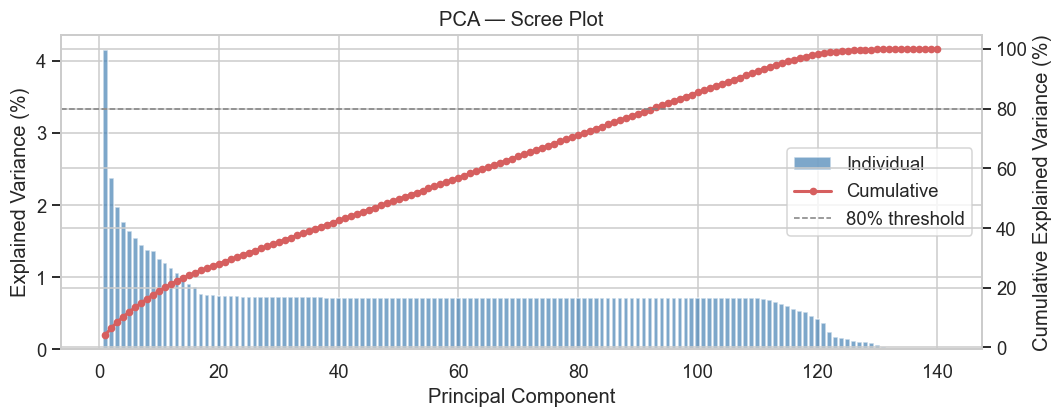

Components needed for 80% variance: 93


In [13]:
# Scree plot
evr = pca.explained_variance_ratio_
cumulative = np.cumsum(evr)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(range(1, len(evr) + 1), evr * 100, color='steelblue', alpha=0.7, label='Individual')
ax2 = ax.twinx()
ax2.plot(range(1, len(cumulative) + 1), cumulative * 100, 'r-o',
         markersize=4, lw=2, label='Cumulative')
ax2.axhline(80, color='grey', lw=1, linestyle='--', label='80% threshold')
ax.set_xlabel('Principal Component')
ax.set_ylabel('Explained Variance (%)')
ax2.set_ylabel('Cumulative Explained Variance (%)')
ax.set_title('PCA — Scree Plot')
lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, loc='center right')
plt.tight_layout()
plt.show()

n_80 = np.argmax(cumulative >= 0.80) + 1
print(f'Components needed for 80% variance: {n_80}')

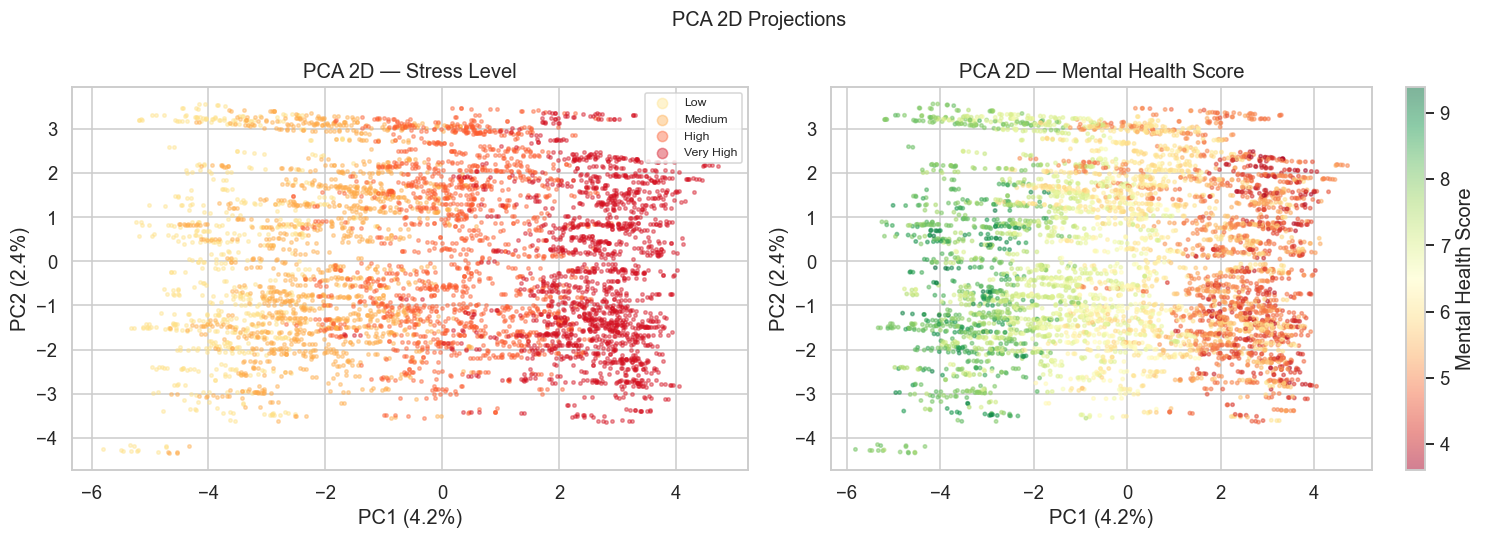

In [14]:
# PCA 2D scatter — coloured by Stress Level
stress_enc = df['Stress_Level_Enc'].values
mental_score = df[TARGET].values
stress_palette = sns.color_palette('YlOrRd', 4)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for j, lvl in enumerate(STRESS_ORDER):
    mask = df['Stress_Level'] == lvl
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1],
               s=5, alpha=0.4, color=stress_palette[j], label=lvl)
ax.set_xlabel(f'PC1 ({evr[0]*100:.1f}%)')
ax.set_ylabel(f'PC2 ({evr[1]*100:.1f}%)')
ax.set_title('PCA 2D — Stress Level')
ax.legend(markerscale=3, fontsize=8)

# PCA 2D scatter — coloured by Mental Health Score
ax = axes[1]
sc = ax.scatter(X_pca[:, 0], X_pca[:, 1],
                c=mental_score, cmap='RdYlGn',
                s=5, alpha=0.5)
plt.colorbar(sc, ax=ax, label='Mental Health Score')
ax.set_xlabel(f'PC1 ({evr[0]*100:.1f}%)')
ax.set_ylabel(f'PC2 ({evr[1]*100:.1f}%)')
ax.set_title('PCA 2D — Mental Health Score')

fig.suptitle('PCA 2D Projections', fontsize=13)
plt.tight_layout()
plt.show()

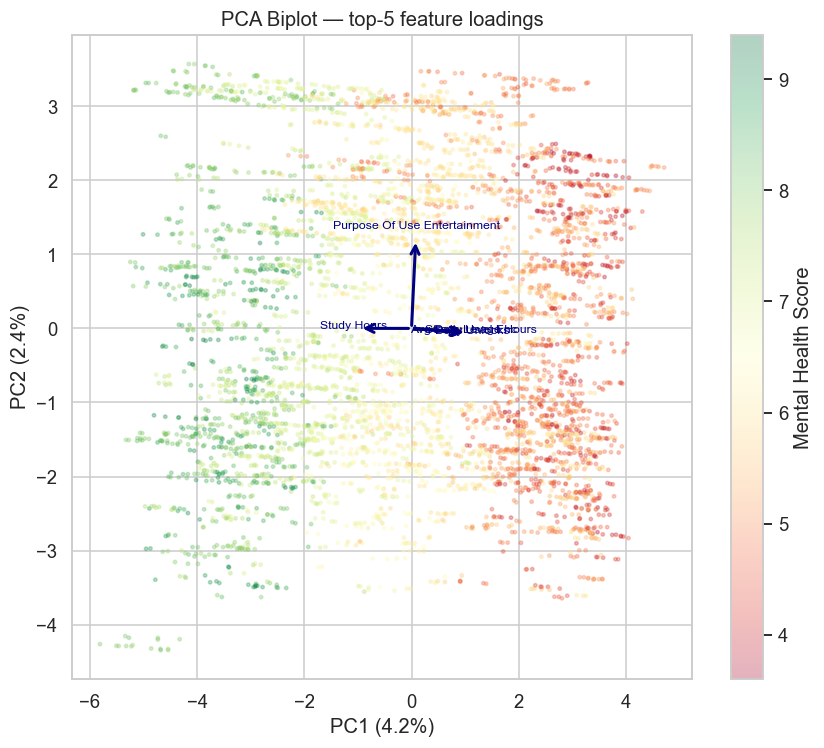

In [15]:
# Biplot — top-5 loading arrows on PC1/PC2
loadings = pca.components_.T  # shape: (n_features, n_components)
loading_df = pd.DataFrame(loadings[:, :2], index=feature_names, columns=['PC1', 'PC2'])
loading_magnitude = np.sqrt(loading_df['PC1']**2 + loading_df['PC2']**2)
top5_features = loading_magnitude.nlargest(5).index.tolist()

fig, ax = plt.subplots(figsize=(8, 7))
sc = ax.scatter(X_pca[:, 0], X_pca[:, 1],
                c=mental_score, cmap='RdYlGn', s=5, alpha=0.3)
plt.colorbar(sc, ax=ax, label='Mental Health Score')

scale = np.abs(X_pca[:, :2]).max() * 0.45
for feat in top5_features:
    arrow = loading_df.loc[feat]
    ax.annotate('', xy=(arrow['PC1'] * scale, arrow['PC2'] * scale),
                xytext=(0, 0),
                arrowprops=dict(arrowstyle='->', color='navy', lw=2))
    ax.text(arrow['PC1'] * scale * 1.12, arrow['PC2'] * scale * 1.12,
            feat.replace('_', ' '), fontsize=8, color='navy', ha='center')

ax.set_xlabel(f'PC1 ({evr[0]*100:.1f}%)')
ax.set_ylabel(f'PC2 ({evr[1]*100:.1f}%)')
ax.set_title('PCA Biplot — top-5 feature loadings')
plt.tight_layout()
plt.show()

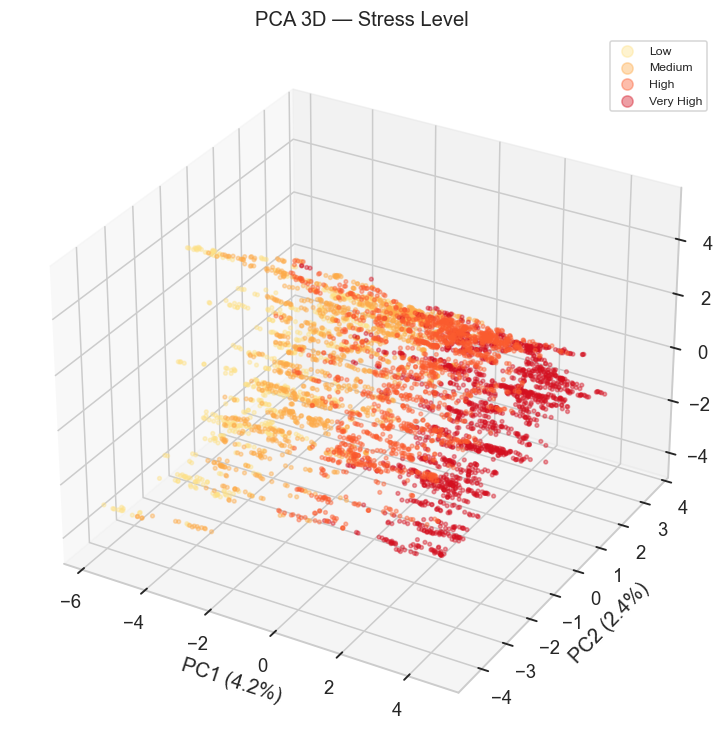

In [16]:
# PCA 3D scatter — coloured by Stress Level
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection='3d')

for j, lvl in enumerate(STRESS_ORDER):
    mask = df['Stress_Level'] == lvl
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1], X_pca[mask, 2],
               s=6, alpha=0.4, color=stress_palette[j], label=lvl)

ax.set_xlabel(f'PC1 ({evr[0]*100:.1f}%)')
ax.set_ylabel(f'PC2 ({evr[1]*100:.1f}%)')
ax.set_zlabel(f'PC3 ({evr[2]*100:.1f}%)')
ax.set_title('PCA 3D — Stress Level')
ax.legend(markerscale=3, fontsize=8)
plt.tight_layout()
plt.show()

In [17]:
# Loading table: feature contributions to PC1 and PC2
loading_display = loading_df.sort_values('PC1', key=abs, ascending=False).head(12)
loading_display.style\
    .format('{:.3f}')\
    .background_gradient(cmap='coolwarm', axis=0)

,PC1,PC2
Avg_Daily_Usage_Hours,0.396,-0.021
Daily_Unlocks,0.387,-0.022
Stress_Level_Enc,0.379,-0.019
Study_Hours,-0.371,0.000
Sleep_Hours_Per_Night,-0.364,0.042
Mental_Health_Score,-0.363,-0.034
Physical_Activity_Hours,-0.281,0.022
Most_Used_Platform_WhatsApp,0.080,-0.049
Country_Japan,-0.072,0.015
Country_Denmark,-0.072,-0.048


## 8. t-SNE — Non-linear Embedding

In [18]:
tsne = TSNE(n_components=2, perplexity=30, random_state=42, n_jobs=-1)
X_tsne = tsne.fit_transform(X_scaled)
print('t-SNE embedding shape:', X_tsne.shape)

t-SNE embedding shape: (5000, 2)


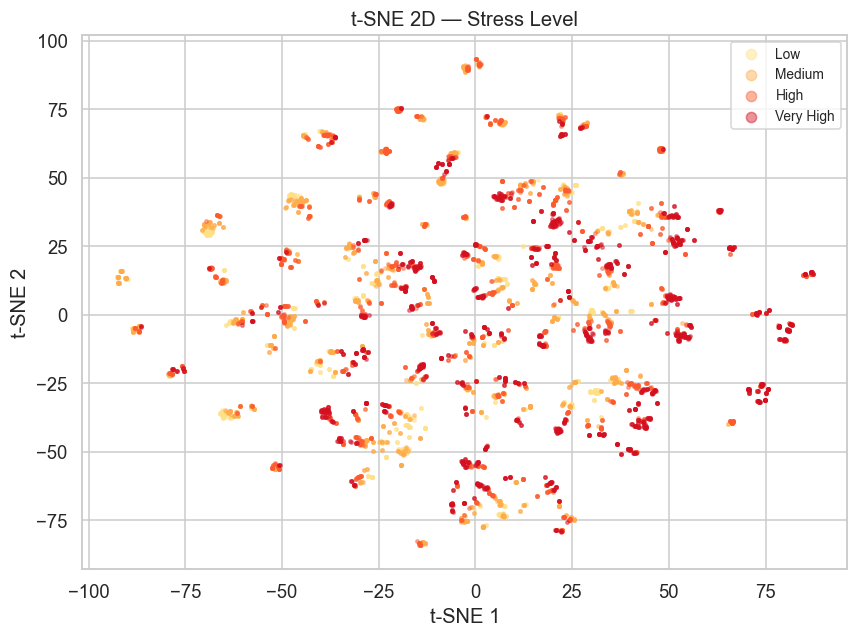

In [19]:
# t-SNE coloured by Stress Level
fig, ax = plt.subplots(figsize=(8, 6))
for j, lvl in enumerate(STRESS_ORDER):
    mask = df['Stress_Level'] == lvl
    ax.scatter(X_tsne[mask, 0], X_tsne[mask, 1],
               s=5, alpha=0.45, color=stress_palette[j], label=lvl)
ax.set_title('t-SNE 2D — Stress Level')
ax.set_xlabel('t-SNE 1')
ax.set_ylabel('t-SNE 2')
ax.legend(markerscale=3, fontsize=9)
plt.tight_layout()
plt.show()

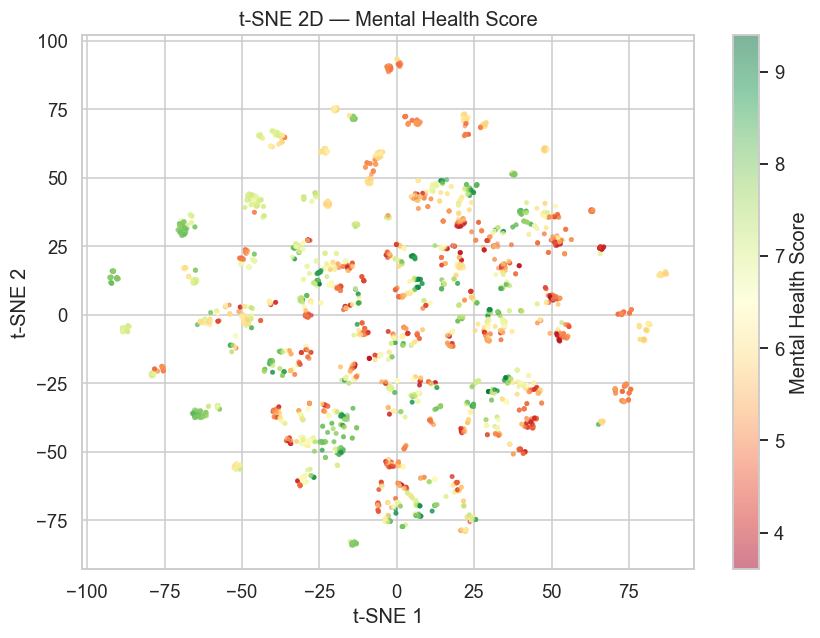

In [20]:
# t-SNE coloured by Mental Health Score
fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(X_tsne[:, 0], X_tsne[:, 1],
                c=mental_score, cmap='RdYlGn', s=5, alpha=0.5)
plt.colorbar(sc, ax=ax, label='Mental Health Score')
ax.set_title('t-SNE 2D — Mental Health Score')
ax.set_xlabel('t-SNE 1')
ax.set_ylabel('t-SNE 2')
plt.tight_layout()
plt.show()

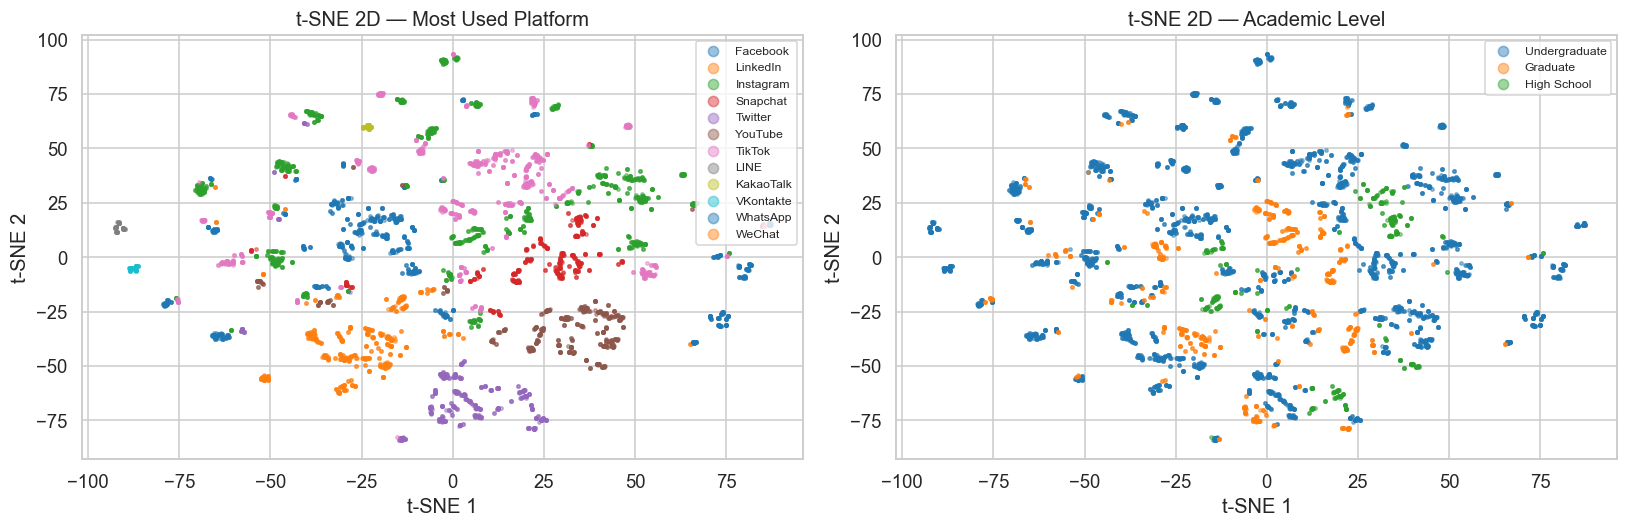

In [21]:
# t-SNE coloured by Most Used Platform and Academic Level
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, col in zip(axes, ['Most_Used_Platform', 'Academic_Level']):
    categories = df[col].unique()
    palette = dict(zip(categories, sns.color_palette('tab10', len(categories))))
    for cat in categories:
        mask = df[col] == cat
        ax.scatter(X_tsne[mask, 0], X_tsne[mask, 1],
                   s=5, alpha=0.45, color=palette[cat], label=cat)
    ax.set_title(f't-SNE 2D — {col.replace("_", " ")}')
    ax.set_xlabel('t-SNE 1')
    ax.set_ylabel('t-SNE 2')
    ax.legend(markerscale=3, fontsize=8)

plt.tight_layout()
plt.show()

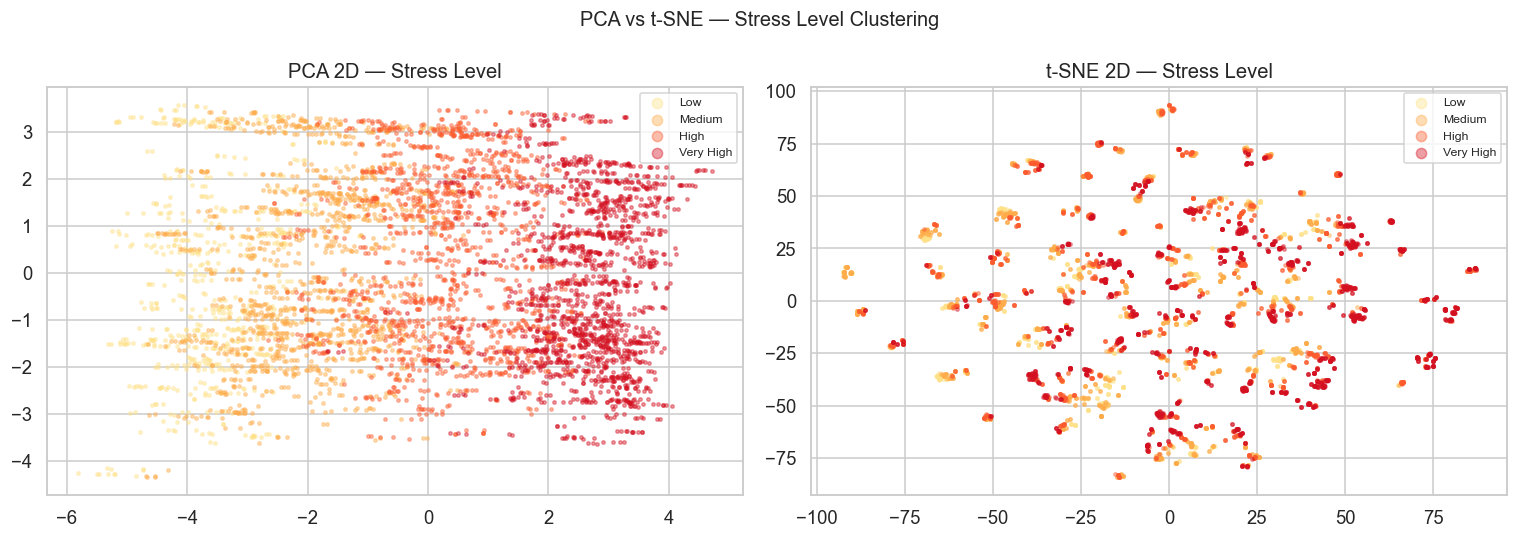

In [22]:
# Side-by-side: PCA vs t-SNE coloured by Stress Level
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, coords, title in [
    (axes[0], X_pca[:, :2], 'PCA 2D'),
    (axes[1], X_tsne,       't-SNE 2D'),
]:
    for j, lvl in enumerate(STRESS_ORDER):
        mask = df['Stress_Level'] == lvl
        ax.scatter(coords[mask, 0], coords[mask, 1],
                   s=5, alpha=0.4, color=stress_palette[j], label=lvl)
    ax.set_title(f'{title} — Stress Level')
    ax.legend(markerscale=3, fontsize=8)

fig.suptitle('PCA vs t-SNE — Stress Level Clustering', fontsize=13)
plt.tight_layout()
plt.show()

## 9. Correlation Between Reduced Dimensions and Target

**Understanding the p-value.** Here each reduced dimension (PCA / t-SNE) is correlated with the target. The *null hypothesis* is **no correlation**; the **p-value** is the chance of observing this correlation by luck under that null. **p ≤ 0.05** flags a statistically significant association.

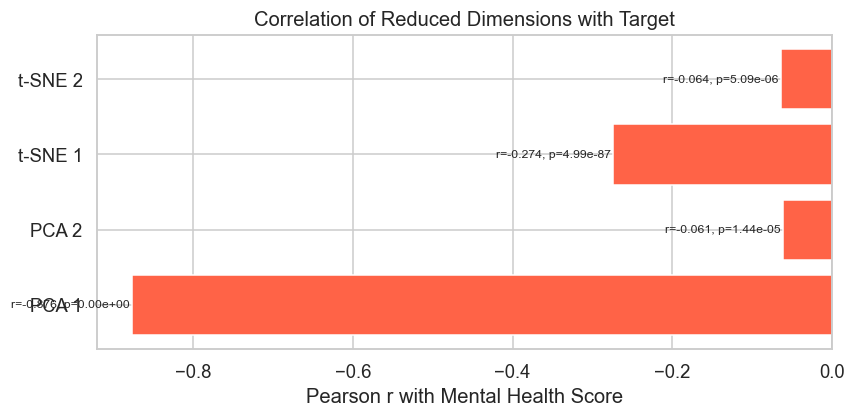

Method Dimension  Pearson r      p-value
   PCA     PCA 1  -0.876091 0.000000e+00
   PCA     PCA 2  -0.061299 1.441250e-05
 t-SNE   t-SNE 1  -0.274332 4.992520e-87
 t-SNE   t-SNE 2  -0.064450 5.093149e-06


In [23]:
results = []
for name, coords in [('PCA', X_pca[:, :2]), ('t-SNE', X_tsne)]:
    for dim_i in range(2):
        r, p = stats.pearsonr(coords[:, dim_i], mental_score)
        results.append({'Method': name, 'Dimension': f'{name} {dim_i+1}',
                        'Pearson r': r, 'p-value': p})

res_df = pd.DataFrame(results)

fig, ax = plt.subplots(figsize=(8, 4))
colors = ['steelblue' if r >= 0 else 'tomato' for r in res_df['Pearson r']]
bars = ax.barh(res_df['Dimension'], res_df['Pearson r'], color=colors)
ax.axvline(0, color='black', lw=0.8)
for bar, row in zip(bars, res_df.itertuples()):
    x = bar.get_width()
    p_str = f'p={row._4:.2e}' if row._4 < 0.001 else f'p={row._4:.4f}'
    ax.text(x + (0.003 if x >= 0 else -0.003), bar.get_y() + bar.get_height() / 2,
            f'r={x:.3f}, {p_str}', va='center', ha='left' if x >= 0 else 'right', fontsize=8)
ax.set_xlabel('Pearson r with Mental Health Score')
ax.set_title('Correlation of Reduced Dimensions with Target')
plt.tight_layout()
plt.show()

print(res_df.to_string(index=False))

## 10. Feature Selection

### 10a. Filter Method — Mutual Information Regression

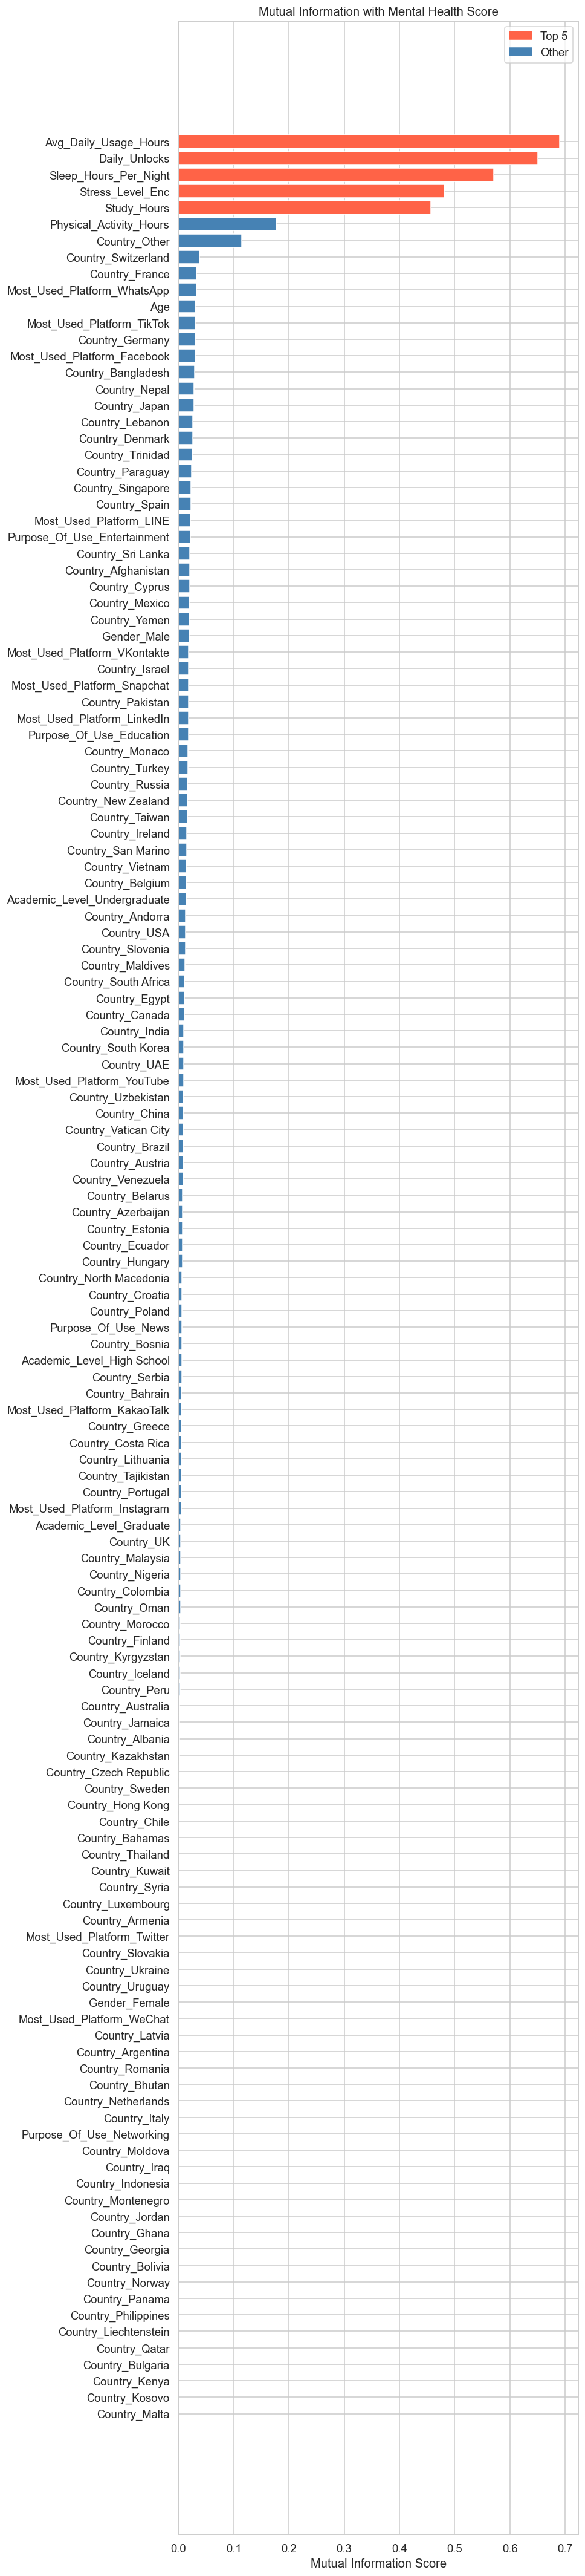

In [24]:
# Exclude target from feature matrix
target_idx = feature_names.index(TARGET)
X_for_selection = np.delete(X_scaled, target_idx, axis=1)
feat_names_no_target = [f for f in feature_names if f != TARGET]
y = mental_score

mi_scores = mutual_info_regression(X_for_selection, y, random_state=42)
mi_df = pd.DataFrame({'Feature': feat_names_no_target, 'MI Score': mi_scores})\
          .sort_values('MI Score', ascending=True)

fig, ax = plt.subplots(figsize=(9, max(5, len(mi_df) * 0.28)))
colors = ['tomato' if s >= mi_df['MI Score'].nlargest(5).min() else 'steelblue'
          for s in mi_df['MI Score']]
ax.barh(mi_df['Feature'], mi_df['MI Score'], color=colors)
ax.set_xlabel('Mutual Information Score')
ax.set_title('Mutual Information with Mental Health Score')
import matplotlib.patches as mpatches
ax.legend(handles=[
    mpatches.Patch(color='tomato', label='Top 5'),
    mpatches.Patch(color='steelblue', label='Other'),
])
plt.tight_layout()
plt.show()

### 10b. Wrapper Method — RFE & RFECV

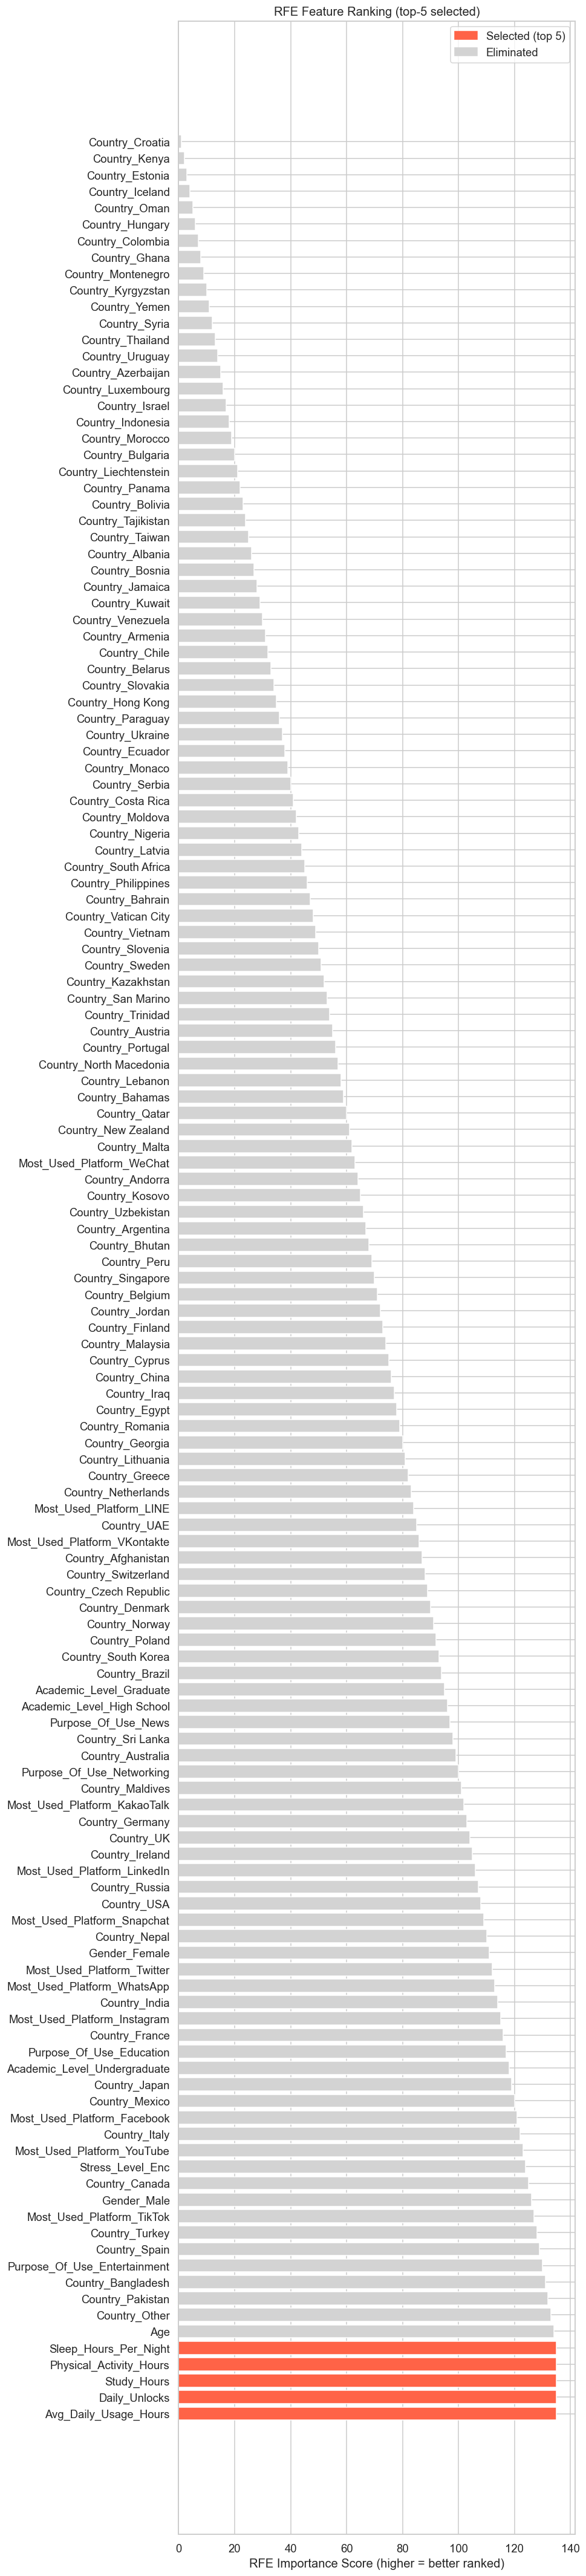

RFE selected features:
['Avg_Daily_Usage_Hours', 'Daily_Unlocks', 'Study_Hours', 'Physical_Activity_Hours', 'Sleep_Hours_Per_Night']


In [25]:
rf_base = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)

rfe = RFE(estimator=rf_base, n_features_to_select=5)
rfe.fit(X_for_selection, y)

rfe_df = pd.DataFrame({
    'Feature': feat_names_no_target,
    'Selected': rfe.support_,
    'Rank': rfe.ranking_
}).sort_values('Rank')

fig, ax = plt.subplots(figsize=(9, max(5, len(rfe_df) * 0.28)))
colors = ['tomato' if s else 'lightgrey' for s in rfe_df['Selected']]
ax.barh(rfe_df['Feature'], rfe_df['Rank'].max() + 1 - rfe_df['Rank'], color=colors)
ax.set_xlabel('RFE Importance Score (higher = better ranked)')
ax.set_title('RFE Feature Ranking (top-5 selected)')
ax.legend(handles=[
    mpatches.Patch(color='tomato', label='Selected (top 5)'),
    mpatches.Patch(color='lightgrey', label='Eliminated'),
])
plt.tight_layout()
plt.show()

print('RFE selected features:')
print(rfe_df[rfe_df['Selected']]['Feature'].tolist())

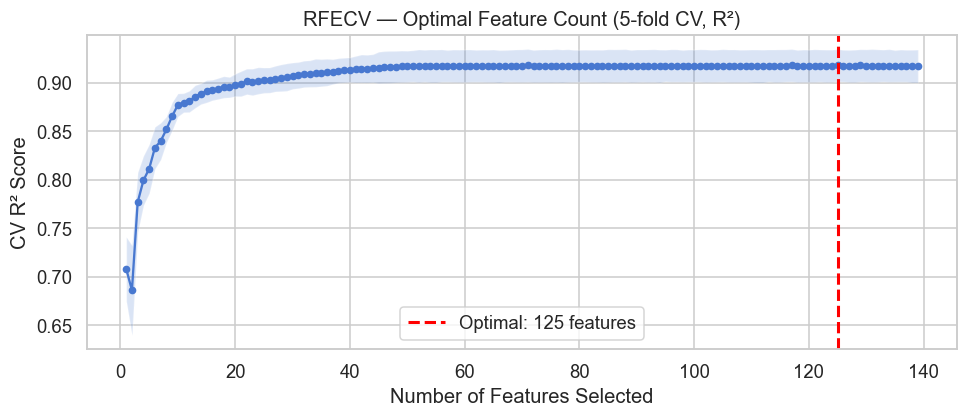

Optimal number of features: 125


In [26]:
# RFECV — find optimal number of features automatically
rfecv = RFECV(
    estimator=RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1),
    step=1,
    cv=KFold(5),
    scoring='r2',
    min_features_to_select=1,
    n_jobs=-1
)
rfecv.fit(X_for_selection, y)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(range(1, len(rfecv.cv_results_['mean_test_score']) + 1),
        rfecv.cv_results_['mean_test_score'], 'b-o', markersize=4)
ax.fill_between(
    range(1, len(rfecv.cv_results_['mean_test_score']) + 1),
    rfecv.cv_results_['mean_test_score'] - rfecv.cv_results_['std_test_score'],
    rfecv.cv_results_['mean_test_score'] + rfecv.cv_results_['std_test_score'],
    alpha=0.2
)
ax.axvline(rfecv.n_features_, color='red', lw=2, linestyle='--',
           label=f'Optimal: {rfecv.n_features_} features')
ax.set_xlabel('Number of Features Selected')
ax.set_ylabel('CV R² Score')
ax.set_title('RFECV — Optimal Feature Count (5-fold CV, R²)')
ax.legend()
plt.tight_layout()
plt.show()

print(f'Optimal number of features: {rfecv.n_features_}')

### 10c. Embedded Method — Random Forest Importances

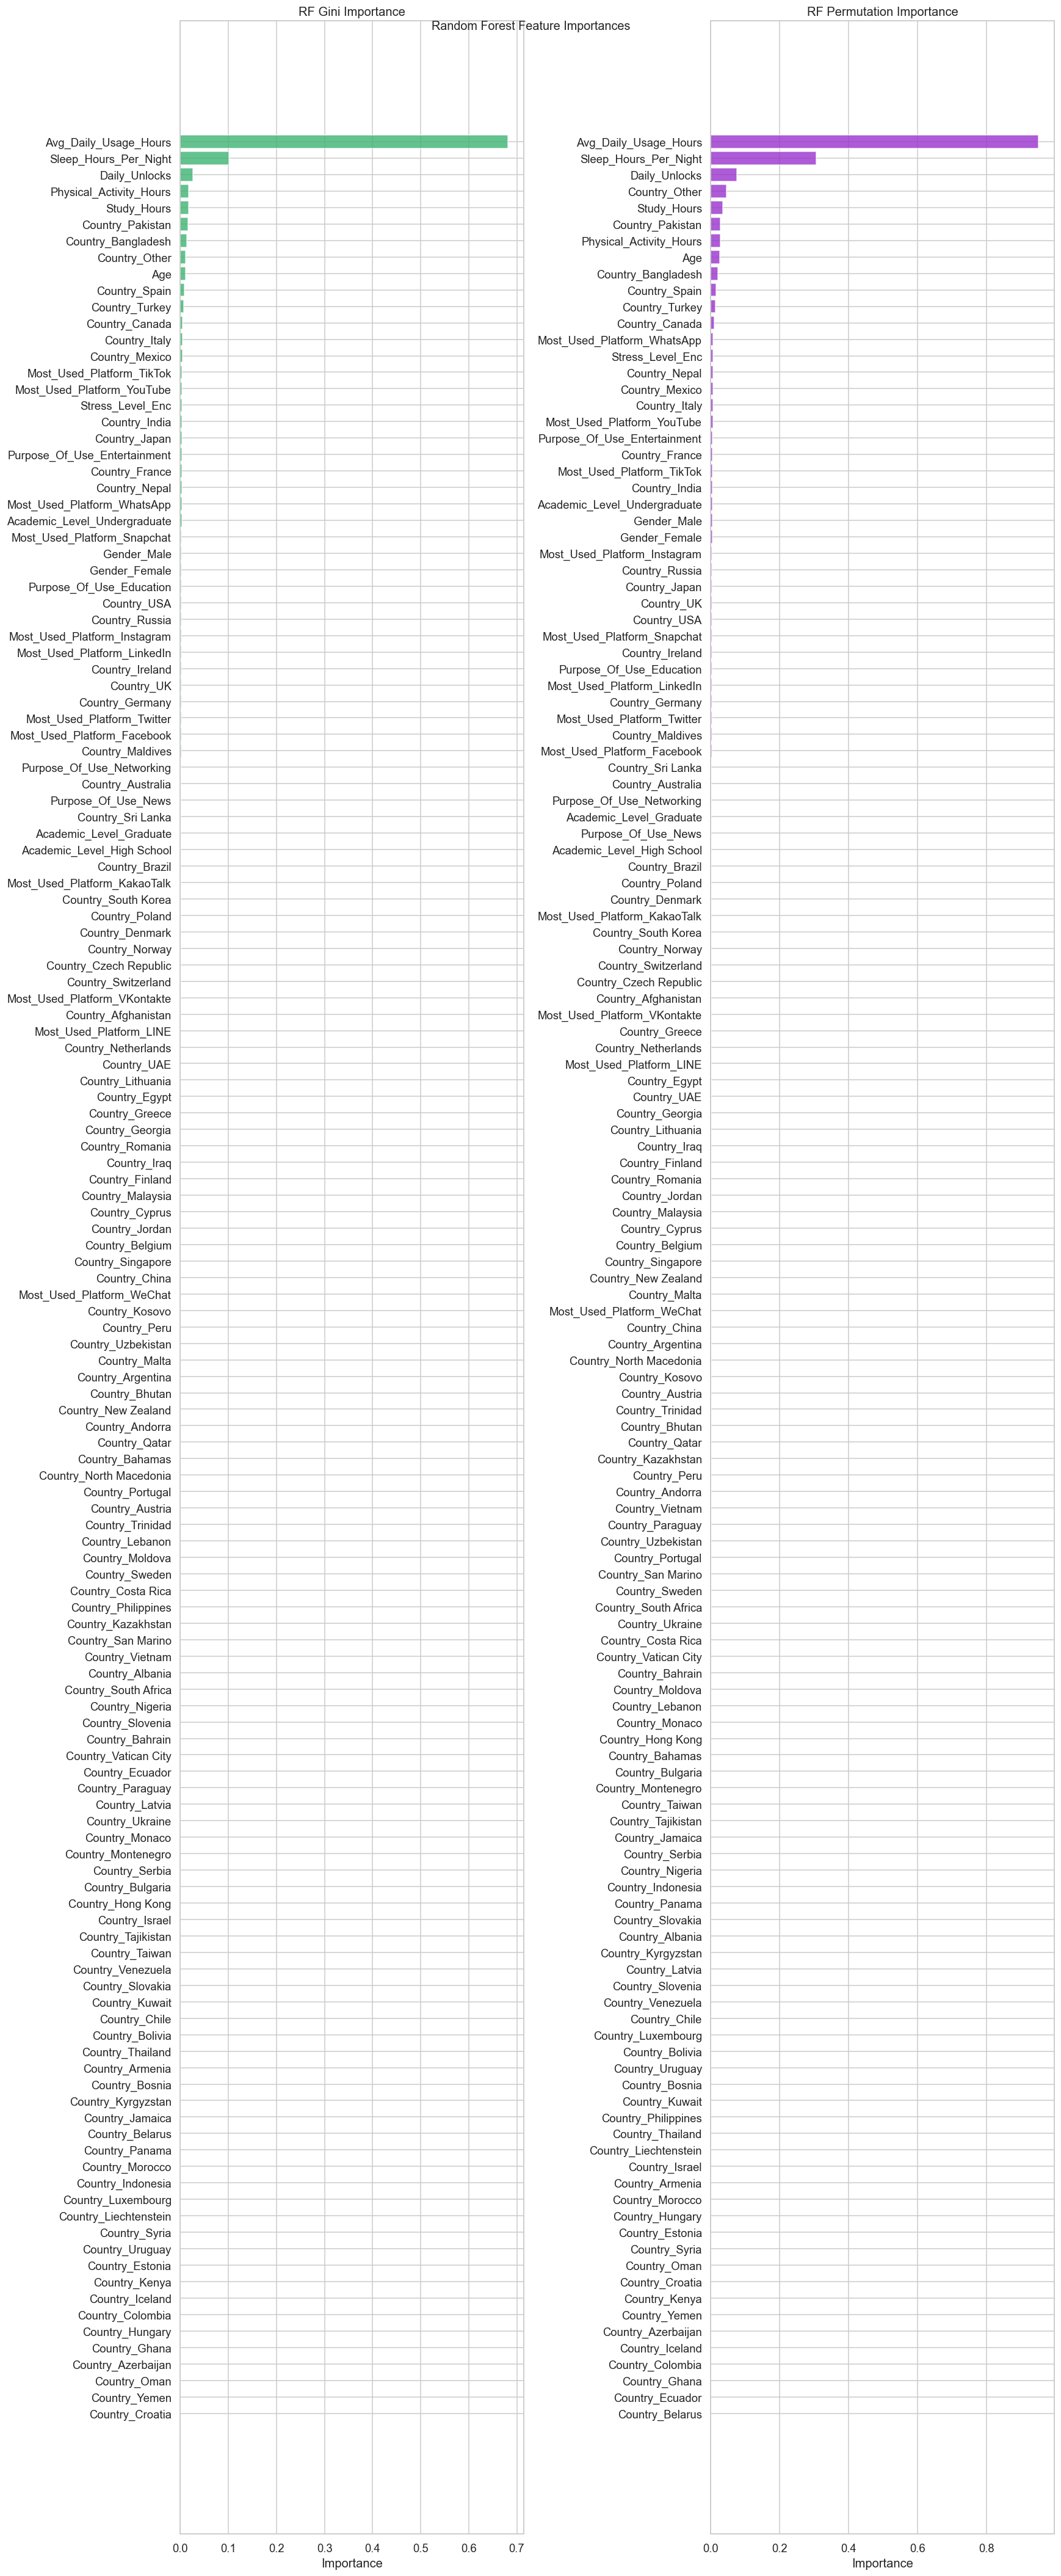

In [27]:
rf_full = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf_full.fit(X_for_selection, y)

gini_imp = pd.Series(rf_full.feature_importances_, index=feat_names_no_target)\
             .sort_values(ascending=False)

perm_result = permutation_importance(
    rf_full, X_for_selection, y,
    n_repeats=20, random_state=42, n_jobs=-1
)
perm_imp = pd.Series(perm_result.importances_mean, index=feat_names_no_target)\
             .sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, max(5, len(gini_imp) * 0.28)))

for ax, imp, title, color in [
    (axes[0], gini_imp.sort_values(), 'Gini Importance', 'mediumseagreen'),
    (axes[1], perm_imp.sort_values(), 'Permutation Importance', 'darkorchid'),
]:
    ax.barh(imp.index, imp.values, color=color, alpha=0.8)
    ax.set_title(f'RF {title}')
    ax.set_xlabel('Importance')

fig.suptitle('Random Forest Feature Importances', fontsize=13)
plt.tight_layout()
plt.show()

### 10d. Summary Comparison Table

In [28]:
# Build unified ranking table
mi_rank   = mi_df.set_index('Feature')['MI Score']\
                  .rank(ascending=False).astype(int)
gini_rank = gini_imp.rank(ascending=False).astype(int)
perm_rank = perm_imp.rank(ascending=False).astype(int)
rfe_selected = pd.Series(
    {row['Feature']: '✓' if row['Selected'] else '✗'
     for _, row in rfe_df.iterrows()}
)

summary_table = pd.DataFrame({
    'MI Rank': mi_rank,
    'RFE Selected': rfe_selected,
    'Gini Rank': gini_rank,
    'Perm Rank': perm_rank,
})

# Consensus: top-5 in at least 2 of the 3 rank-based methods
def top5(rank_series):
    return rank_series <= 5

summary_table['Consensus Score'] = (
    top5(summary_table['MI Rank']).astype(int) +
    (summary_table['RFE Selected'] == '✓').astype(int) +
    top5(summary_table['Gini Rank']).astype(int) +
    top5(summary_table['Perm Rank']).astype(int)
)

summary_table = summary_table.sort_values('Consensus Score', ascending=False)

print('=== Feature Selection Summary ===')
print(summary_table.to_string())

consensus_features = summary_table[summary_table['Consensus Score'] >= 2].index.tolist()
print(f'\nConsensus top features (≥2 methods in top-5): {consensus_features}')

=== Feature Selection Summary ===
                              MI Rank RFE Selected  Gini Rank  Perm Rank  Consensus Score
Study_Hours                         5            ✓          5          5                4
Sleep_Hours_Per_Night               3            ✓          2          2                4
Avg_Daily_Usage_Hours               1            ✓          1          1                4
Daily_Unlocks                       2            ✓          3          3                4
Physical_Activity_Hours             6            ✓          4          7                2
Stress_Level_Enc                    4            ✗         17         14                1
Country_Other                       7            ✗          8          4                1
Country_South Africa               52            ✗         95         90                0
Country_San Marino                 44            ✗         92         88                0
Country_Serbia                     76            ✗        106     

In [29]:
# Styled summary table
def highlight_consensus(row):
    color = 'background-color: #d4edda' if row['Consensus Score'] >= 2 else ''
    return [color] * len(row)

summary_table.style\
    .apply(highlight_consensus, axis=1)\
    .background_gradient(cmap='Blues', subset=['Consensus Score'])

,MI Rank,RFE Selected,Gini Rank,Perm Rank,Consensus Score
Study_Hours,5,✓,5,5,4
Sleep_Hours_Per_Night,3,✓,2,2,4
Avg_Daily_Usage_Hours,1,✓,1,1,4
Daily_Unlocks,2,✓,3,3,4
Physical_Activity_Hours,6,✓,4,7,2
Stress_Level_Enc,4,✗,17,14,1
Country_Other,7,✗,8,4,1
Country_South Africa,52,✗,95,90,0
Country_San Marino,44,✗,92,88,0
Country_Serbia,76,✗,106,105,0


## 11. Geographic Distribution

Geographic plots reveal whether a student's **country** is associated with differences in mental health outcomes, social media habits, and behaviour patterns.
*Countries labelled "Other" in the dataset are excluded from all maps.*

In [30]:
import os, pooch, warnings
import geopandas as gpd
import plotly.express as px
import pycountry

# Download/cache Natural Earth 110m countries (geopandas ≥1.0 removed the bundled copy)
_world_zip = pooch.retrieve(
    url='https://naciscdn.org/naturalearth/110m/cultural/ne_110m_admin_0_countries.zip',
    known_hash='0f243aeac8ac6cf26f0417285b0bd33ac47f1b5bdb719fd3e0df37d03ea37110',
    path=os.path.join('..', 'dataset'),
    fname='ne_110m_admin_0_countries.zip',
)
world = gpd.read_file(_world_zip)
world = world[world['NAME'] != 'Antarctica'].copy()
# ISO_A3_EH handles France/Norway; ADM0_A3 covers the last remaining -99 edge cases
world['merge_iso'] = world['ISO_A3_EH'].where(world['ISO_A3_EH'] != '-99', world['ADM0_A3'])
WORLD_ISO_COL = 'merge_iso'   # use this when joining country_stats → world

# Aggregate per real country (exclude unmappable 'Other')
geo_df = df[df['Country'] != 'Other'].copy()

country_stats = (
    geo_df.groupby('Country')
    .agg(
        mean_mh=('Mental_Health_Score', 'mean'),
        mean_usage=('Avg_Daily_Usage_Hours', 'mean'),
        mean_study=('Study_Hours', 'mean'),
        mean_sleep=('Sleep_Hours_Per_Night', 'mean'),
        count=('Mental_Health_Score', 'count'),
        top_platform=('Most_Used_Platform', lambda x: x.mode()[0])
    )
    .reset_index()
)

print(f'Countries with data (excluding "Other"): {len(country_stats)}')
country_stats.head()

Countries with data (excluding "Other"): 110


,Country,mean_mh,mean_usage,mean_study,mean_sleep,count,top_platform
0,Afghanistan,7.000000,2.9875,5.350000,7.05,8,LinkedIn
1,Albania,6.066667,4.9000,3.966667,5.80,3,TikTok
2,Andorra,5.060000,5.4000,3.500000,5.48,5,TikTok
3,Argentina,4.960000,5.6200,2.120000,5.24,5,TikTok
4,Armenia,5.000000,5.9000,1.000000,5.20,1,Instagram


In [31]:
MANUAL_OVERRIDES = {
    'USA':          'United States',
    'UK':           'United Kingdom',
    'Turkey':       'Turkiye',
    'UAE':          'United Arab Emirates',
    'South Korea':  'Korea, Republic of',
    'North Korea':  "Korea, Democratic People's Republic of",
    'Iran':         'Iran, Islamic Republic of',
    'Russia':       'Russian Federation',
    'Bolivia':      'Bolivia, Plurinational State of',
    'Venezuela':    'Venezuela, Bolivarian Republic of',
    'Syria':        'Syrian Arab Republic',
    'Tanzania':     'Tanzania, United Republic of',
    'Laos':         "Lao People's Democratic Republic",
    'Vietnam':      'Viet Nam',
    'Taiwan':       'Taiwan, Province of China',
    'Palestine':    'Palestine, State of',
    'Moldova':      'Moldova, Republic of',
    'Ivory Coast':  "Côte d'Ivoire",
    'Trinidad':     'Trinidad and Tobago',
    'DR Congo':     'Congo, The Democratic Republic of the',
}

def get_iso3(name):
    search_name = MANUAL_OVERRIDES.get(name, name)
    try:
        return pycountry.countries.search_fuzzy(search_name)[0].alpha_3
    except LookupError:
        return None

country_stats['iso_alpha3'] = country_stats['Country'].apply(get_iso3)

unmapped = country_stats[country_stats['iso_alpha3'].isna()]['Country'].tolist()
if unmapped:
    print(f'Could not map {len(unmapped)} country/ies: {unmapped}')
    print('Add them to MANUAL_OVERRIDES or check dataset spelling.')
country_stats = country_stats.dropna(subset=['iso_alpha3']).copy()
print(f'Successfully mapped countries: {len(country_stats)}')

Successfully mapped countries: 110


### 11a. Mean Mental Health Score by Country

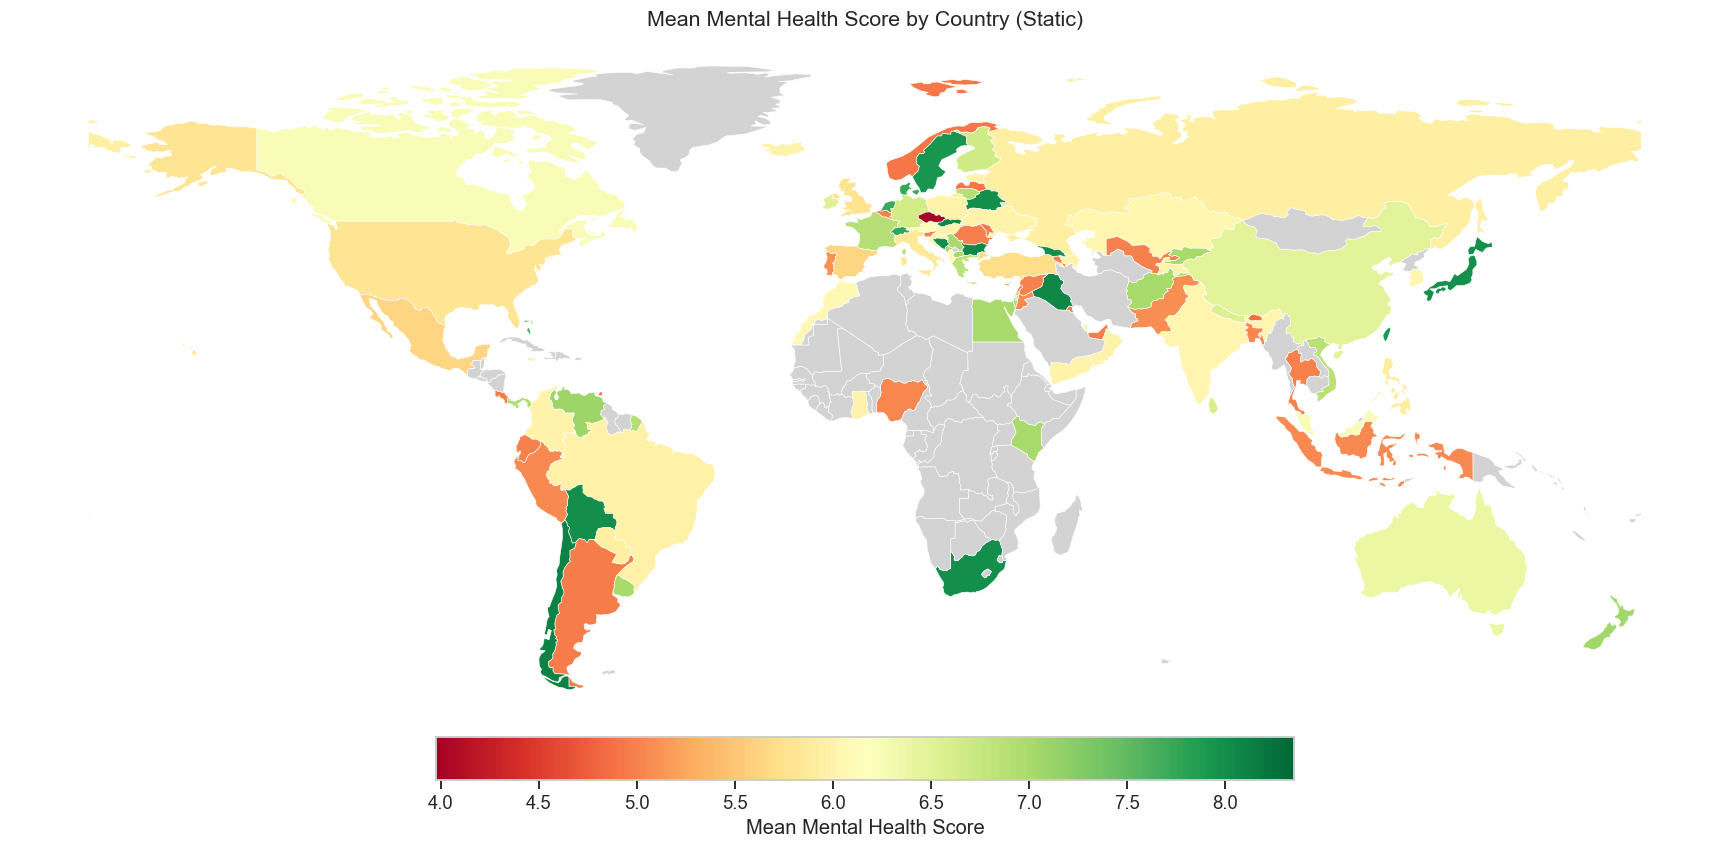

In [32]:
# Shared color scale anchored to the data range
MH_RANGE = [country_stats['mean_mh'].min(), country_stats['mean_mh'].max()]

world_mh = world.merge(
    country_stats[['iso_alpha3', 'mean_mh']],
    left_on=WORLD_ISO_COL, right_on='iso_alpha3', how='left'
)

fig, ax = plt.subplots(1, 1, figsize=(16, 8))
world_mh.plot(
    column='mean_mh',
    cmap='RdYlGn',
    legend=True,
    legend_kwds={
        'label': 'Mean Mental Health Score',
        'orientation': 'horizontal',
        'shrink': 0.5,
        'pad': 0.02,
    },
    vmin=MH_RANGE[0], vmax=MH_RANGE[1],
    missing_kwds={'color': 'lightgrey', 'label': 'No data'},
    edgecolor='white',
    linewidth=0.4,
    ax=ax
)
ax.set_title('Mean Mental Health Score by Country (Static)', fontsize=14)
ax.axis('off')
plt.tight_layout()
plt.show()

In [33]:
fig = px.choropleth(
    country_stats,
    locations='iso_alpha3',
    color='mean_mh',
    hover_name='Country',
    hover_data={
        'iso_alpha3':   False,
        'count':        True,
        'mean_usage':   ':.2f',
        'top_platform': True,
    },
    color_continuous_scale='RdYlGn',
    range_color=MH_RANGE,
    projection='natural earth',
    title='Mean Mental Health Score by Country (Interactive)',
    labels={
        'mean_mh':      'Mean MH Score',
        'count':        'Sample Count',
        'mean_usage':   'Mean Daily Usage (h)',
        'top_platform': 'Top Platform',
    }
)
fig.update_layout(
    coloraxis_colorbar=dict(title='Mean MH Score'),
    margin=dict(l=0, r=0, t=40, b=0),
    height=500,
)
fig.show()

### 11b. Most-Used Social Media Platform by Country

In [34]:
fig = px.choropleth(
    country_stats,
    locations='iso_alpha3',
    color='top_platform',
    hover_name='Country',
    hover_data={'iso_alpha3': False, 'count': True},
    color_discrete_sequence=px.colors.qualitative.Set2,
    projection='natural earth',
    title='Most-Used Social Media Platform by Country',
    labels={'top_platform': 'Platform', 'count': 'Sample Count'}
)
fig.update_layout(
    legend=dict(title='Platform', orientation='v'),
    margin=dict(l=0, r=0, t=40, b=0),
    height=500,
)
fig.show()

### 11c. Country-Level Feature Averages (Small Multiples)

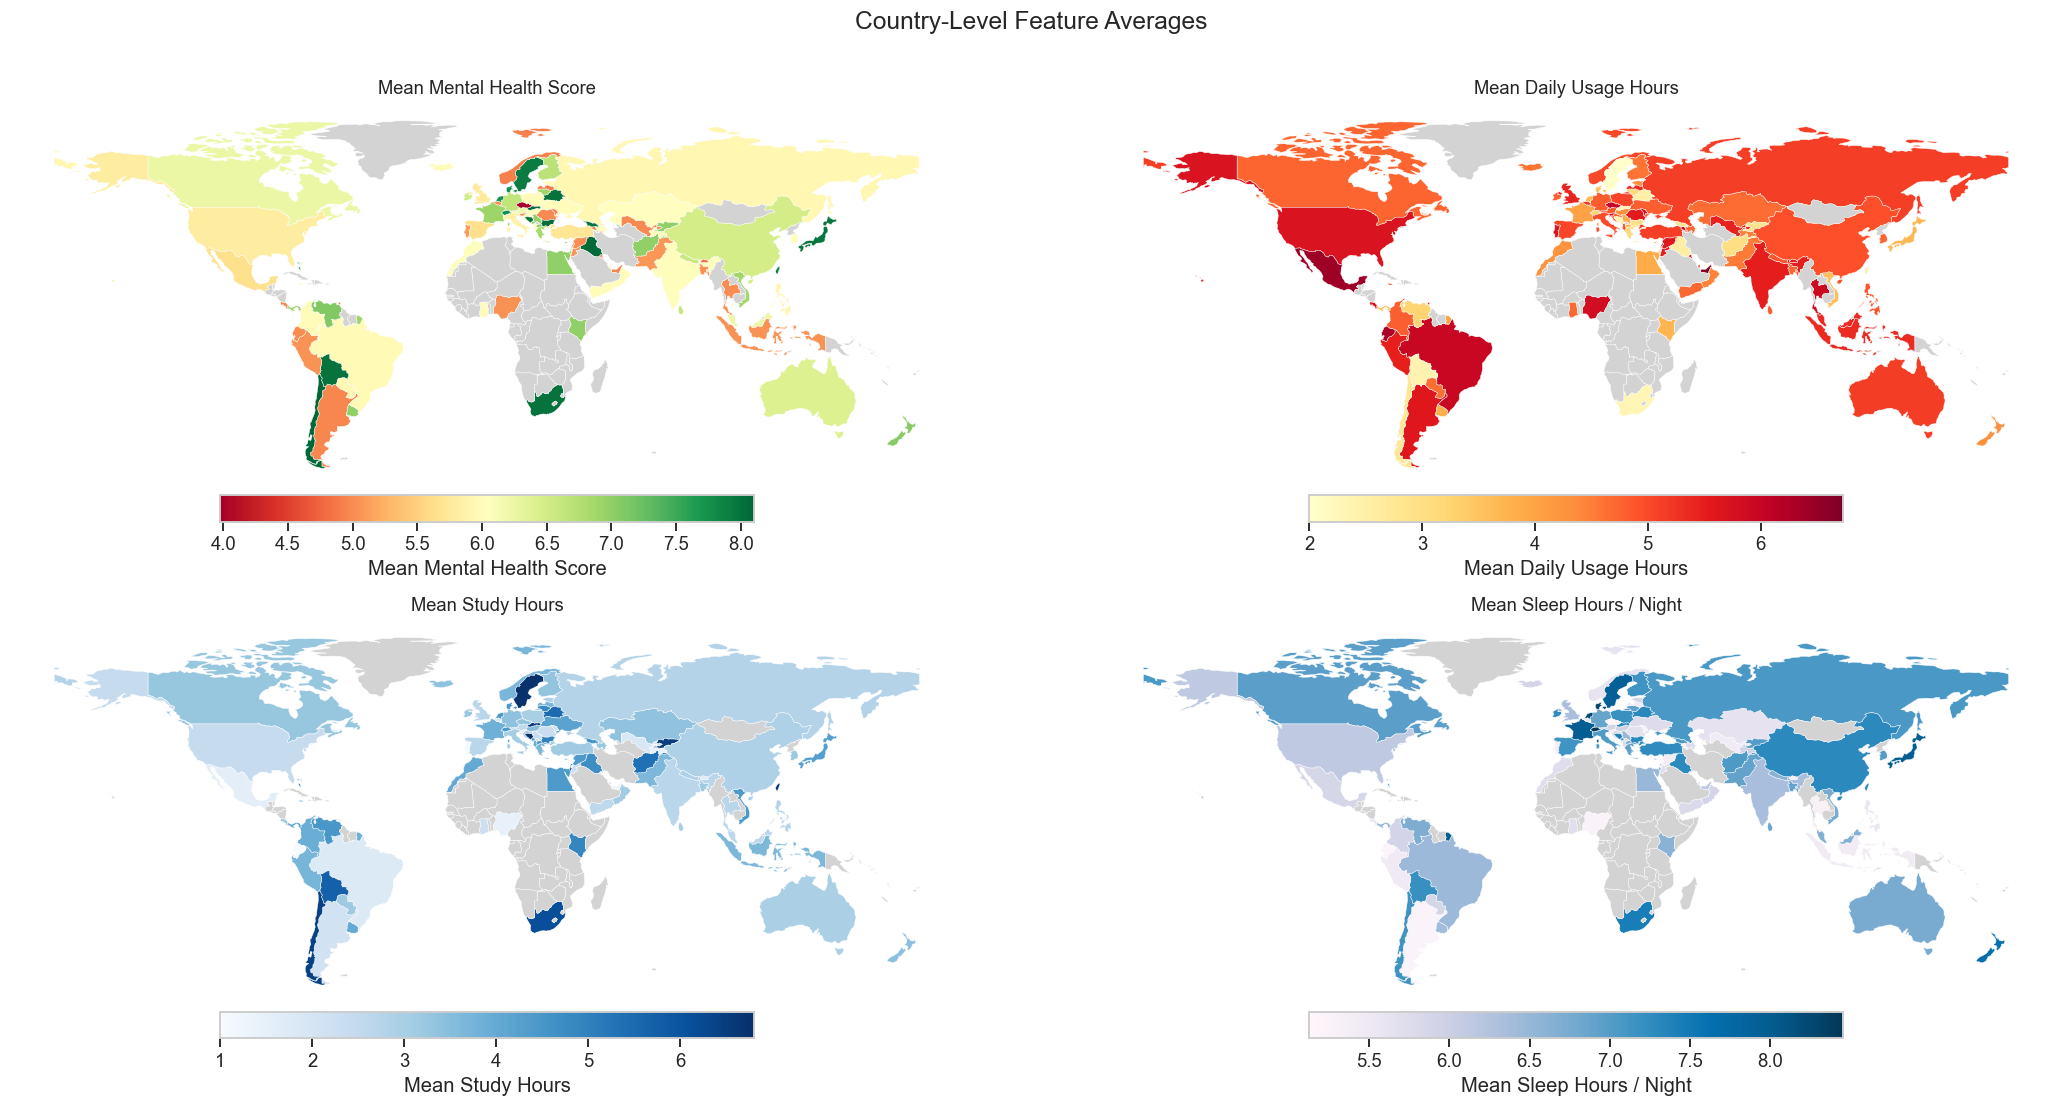

In [35]:
PANELS = [
    ('mean_mh',    'RdYlGn', 'Mean Mental Health Score'),
    ('mean_usage', 'YlOrRd', 'Mean Daily Usage Hours'),
    ('mean_study', 'Blues',  'Mean Study Hours'),
    ('mean_sleep', 'PuBu',   'Mean Sleep Hours / Night'),
]

fig, axes = plt.subplots(2, 2, figsize=(20, 10))
axes = axes.flatten()

for ax, (col, cmap, title) in zip(axes, PANELS):
    merged = world.merge(
        country_stats[['iso_alpha3', col]],
        left_on=WORLD_ISO_COL, right_on='iso_alpha3', how='left'
    )
    merged.plot(
        column=col,
        cmap=cmap,
        legend=True,
        legend_kwds={
            'label': title,
            'orientation': 'horizontal',
            'shrink': 0.5,
            'pad': 0.02,
        },
        missing_kwds={'color': 'lightgrey'},
        edgecolor='white',
        linewidth=0.3,
        ax=ax
    )
    ax.set_title(title, fontsize=12)
    ax.axis('off')

fig.suptitle('Country-Level Feature Averages', fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

### 11d. Bubble Map — Mental Health Score × Sample Size

In [36]:
fig = px.scatter_geo(
    country_stats,
    locations='iso_alpha3',
    color='mean_mh',
    size='count',
    hover_name='Country',
    hover_data={
        'iso_alpha3':  False,
        'mean_study':  ':.2f',
        'mean_mh':     ':.2f',
        'count':       True,
    },
    color_continuous_scale='RdYlGn',
    range_color=MH_RANGE,
    size_max=40,
    projection='natural earth',
    title='Mental Health Score by Country — Bubble Size = Sample Count',
    labels={
        'mean_mh':    'Mean MH Score',
        'mean_study': 'Mean Study Hours',
        'count':      'Sample Count',
    }
)
fig.update_layout(
    coloraxis_colorbar=dict(title='Mean MH Score'),
    margin=dict(l=0, r=0, t=40, b=0),
    height=500,
)
fig.show()